# 영화 대사 코퍼스 기반 텍스트 분류
## 데이터 점검 및 정제

스타워즈 대사를 이용한 선(Good) / 악(Bad) 캐릭터 이진 분류 과제의 **첫 번째 부분**이다.
이 부분에서는 모델을 만들기 전에 제공된 두 CSV 파일(소규모, 대규모)을 점검하고 정제한다.

- 데이터: Cornell Movie-Dialogs Corpus에서 추출된 스타워즈 캐릭터 대사
- 이 부분의 목표: 원본 데이터의 상태와 문제점을 확인하고, 기록 가능한 규칙으로 정제하여 이후 실험에 사용할 데이터를 만든다.
- 정제 과정과 발견한 문제점은 보고서의 데이터 설명과 한계 부분에 그대로 사용한다.

## 라벨 정의

| 라벨 | 값 | 캐릭터 (과제 계획서 기준) |
|---|---|---|
| Good | 1 | LUKE, LEIA |
| Bad | 0 | DARTH VADER, EMPEROR |

캐릭터를 Good/Bad로 나누는 것은 **과제용 라벨링 규칙**일 뿐이다. 캐릭터의 모든 대사가 실제 감정이나 도덕성을 반영한다는 뜻이 아니며,
이후 결과를 일반적인 감정 분석 성능으로 해석하지 않는다.

## 환경 설정

In [5]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

RANDOM_STATE = 42
DATA_DIR = Path(".")  
FILES = {
    "소규모": "starwars_4char_100lines.csv",
    "대규모": "starwars_4char_1000lines.csv",
}

available_fonts = {f.name for f in fm.fontManager.ttflist}
preferred = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans KR", "Noto Sans CJK KR"]
fallback = sorted((n for n in available_fonts if "CJK" in n or "Gothic" in n or "Nanum" in n),
                  key=lambda n: ("CJK" not in n, n))
for font_name in preferred + fallback:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

COLOR = {"Good": "#4C78A8", "Bad": "#E45756"}

## 데이터 불러오기
### 원본 파일 구조

In [6]:
raw = {name: pd.read_csv(DATA_DIR / fname) for name, fname in FILES.items()}

for name, df in raw.items():
    print(f"[{name}] 형태: {df.shape} / 컬럼: {list(df.columns)}")
    print(df.dtypes.to_string(), "\n")

display(raw["소규모"].head())

[소규모] 형태: (125, 4) / 컬럼: ['CharacterName_Clean', 'Label', 'Target', 'Text']
CharacterName_Clean      str
Label                    str
Target                 int64
Text                     str 

[대규모] 형태: (552, 4) / 컬럼: ['CharacterName_Clean', 'Label', 'Target', 'Text']
CharacterName_Clean      str
Label                    str
Target                 int64
Text                     str 



,CharacterName_Clean,Label,Target,Text
0,LUKE,Good,1,"Delly, shhhhhh..."
1,LUKE,Good,1,Delly. I'm... I'm not... Harry wasn't my father. And I'm not... I'm not Luke.
2,LUKE,Good,1,Well... everything. It started coming back a couple of days ago. I remember everything now.
3,LUKE,Good,1,Guess I must've learned.
4,LUKE,Good,1,Thanks.


## 원본 데이터 점검

정제를 하기 전에 먼저 **원본이 라벨 정의와 맞는지** 있는 그대로 확인한다.
여기서 발견한 문제는 데이터를 고치지 않고 기록해 두며, 보고서의 한계 부분에 사용한다.

### 캐릭터별 라벨별 분포

In [7]:
for name, df in raw.items():
    print(f"[{name}] 캐릭터 x 라벨 분포")
    display(pd.crosstab(df["CharacterName_Clean"], [df["Label"], df["Target"]], margins=True))

[소규모] 캐릭터 x 라벨 분포


Label,Bad,Good,All
Target,0,1,
CharacterName_Clean,,,
EMPEROR,25,0,25
LUKE,0,100,100
All,25,100,125


[대규모] 캐릭터 x 라벨 분포


Label,Bad,Good,All
Target,0,1,
CharacterName_Clean,,,
EMPEROR,25,0,25
LEIA,0,177,177
LUKE,0,350,350
All,25,527,552


### 라벨 정의와 실제 데이터의 일치 여부

과제 계획서에서 정의한 캐릭터가 실제 파일에 존재하는지 확인한다.

In [8]:
EXPECTED = {"Good": ["LUKE", "LEIA"], "Bad": ["DARTH VADER", "EMPEROR"]}

rows = []
for name, df in raw.items():
    found = set(df["CharacterName_Clean"].unique())
    for label, chars in EXPECTED.items():
        for ch in chars:
            n = int((df["CharacterName_Clean"] == ch).sum())
            rows.append({"데이터셋": name, "라벨": label, "캐릭터": ch,
                         "존재 여부": "있음" if n > 0 else "없음", "대사 수": n})
    extra = found - {c for cs in EXPECTED.values() for c in cs}
    if extra:
        print(f"[{name}] 계획서에 없는 캐릭터:", extra)

display(pd.DataFrame(rows))

,데이터셋,라벨,캐릭터,존재 여부,대사 수
0,소규모,Good,LUKE,있음,100
1,소규모,Good,LEIA,없음,0
2,소규모,Bad,DARTH VADER,없음,0
3,소규모,Bad,EMPEROR,있음,25
4,대규모,Good,LUKE,있음,350
5,대규모,Good,LEIA,있음,177
6,대규모,Bad,DARTH VADER,없음,0
7,대규모,Bad,EMPEROR,있음,25


### 다른 영화 대사 혼입 가능성

파일이 캐릭터 이름 기준으로만 추출된 것으로 보여, 스타워즈가 아닌 영화의 대사가 섞였을 가능성을 확인한다.
아래는 **키워드 기반의 간단한 추정**이므로 정확한 판정이 아니며, 오탐이 있을 수 있다. 확인된 대사도 삭제하지 않고 그대로 사용한다.

In [9]:
DUNE_KEYWORDS = r"guild|navigator|spice|richesse|telepathy"      # 영화 '듄' 관련 단어
OTHER_FILM_KEYWORDS = r"\bHarry\b|\bDelly\b|\bErnie\b"          # 스타워즈에 나오지 않는 이름

summary = []
examples = []
for name, df in raw.items():
    dune = df[df["Text"].str.contains(DUNE_KEYWORDS, case=False, regex=True)]
    other = df[df["Text"].str.contains(OTHER_FILM_KEYWORDS, regex=True)]
    summary.append({
        "데이터셋": name,
        "듄 키워드 대사": len(dune),
        "듄 키워드 대사의 캐릭터": dict(dune["CharacterName_Clean"].value_counts()),
        "타 영화 이름 키워드 대사": len(other),
        "타 영화 이름 키워드 대사의 캐릭터": dict(other["CharacterName_Clean"].value_counts()),
    })
    examples.append((name, dune, other))

display(pd.DataFrame(summary))

name, dune, other = examples[0]
print(f"[{name}] 듄 키워드 예시")
display(dune[["CharacterName_Clean", "Text"]].assign(Text=lambda d: d["Text"].str.slice(0, 100)))
print(f"[{name}] 타 영화 이름 키워드 예시")
display(other[["CharacterName_Clean", "Text"]].assign(Text=lambda d: d["Text"].str.slice(0, 100)))

,데이터셋,듄 키워드 대사,듄 키워드 대사의 캐릭터,타 영화 이름 키워드 대사,타 영화 이름 키워드 대사의 캐릭터
0,소규모,4,{'EMPEROR': 4},8,{'LUKE': 8}
1,대규모,5,"{'EMPEROR': 4, 'LEIA': 1}",9,{'LUKE': 9}


[소규모] 듄 키워드 예시


,CharacterName_Clean,Text
103,EMPEROR,I shall want telepathy during his visit and a report when we're finished.
104,EMPEROR,A Third Stage Guild Navigator will be here within minutes!
106,EMPEROR,Can you hear me?... If this visit has anything to do with spice... -- The Guild Navigator shudders a
109,EMPEROR,Oh yes? -- NAVIGATOR Better than those on Richesse.. You are transparent... I see many things... I s


[소규모] 타 영화 이름 키워드 예시


,CharacterName_Clean,Text
0,LUKE,"Delly, shhhhhh..."
1,LUKE,Delly. I'm... I'm not... Harry wasn't my father. And I'm not... I'm not Luke.
18,LUKE,"It's gonna cost over nine hundred dollars to open the place, Delly."
51,LUKE,"You're not going anywhere, Harry."
67,LUKE,"I'll be home in a little while, Harry. Don't wait up."
69,LUKE,... Ernie.
76,LUKE,Um... Harry? Did I ever keep the books here?
93,LUKE,"Oh, you mean the suit. Harry kept all my old clothes. Fits okay, but it's a little big."


### 소규모 파일과 대규모 파일의 중복 여부

두 파일이 서로 독립적인 데이터인지 확인한다. 캐릭터별로 같은 대사가 두 파일에 모두 있는지 비교한다.

In [10]:
small, large = raw["소규모"], raw["대규모"]
rows = []
for ch in sorted(set(small["CharacterName_Clean"]) | set(large["CharacterName_Clean"])):
    a = set(small.loc[small["CharacterName_Clean"] == ch, "Text"])
    b = set(large.loc[large["CharacterName_Clean"] == ch, "Text"])
    rows.append({"캐릭터": ch, "소규모 고유 대사 수": len(a), "대규모 고유 대사 수": len(b),
                 "두 파일에 모두 있는 대사 수": len(a & b)})
display(pd.DataFrame(rows))

,캐릭터,소규모 고유 대사 수,대규모 고유 대사 수,두 파일에 모두 있는 대사 수
0,EMPEROR,24,24,24
1,LEIA,0,175,0
2,LUKE,97,342,97


### 점검 결과 요약

위 출력에서 확인한 내용을 정리한다. (구체적인 수치는 위 표를 기준으로 한다.)

- **DARTH VADER(또는 VADER) 대사가 파일에 없다.** 라벨 정의상 Bad는 두 캐릭터이지만 실제 Bad 클래스는 EMPEROR 한 캐릭터뿐이다.
- **Bad 클래스의 수가 두 파일에서 같다.** 대규모 파일에서 늘어난 대사는 모두 Good(LUKE, LEIA)이므로 클래스 불균형이 더 심해진다.
- **다른 영화의 대사가 섞인 것으로 보인다.** EMPEROR에는 영화 '듄' 관련 대사가, LUKE에는 스타워즈에 나오지 않는 이름이 포함된 대사가 있다.
- **소규모 파일은 대규모 파일과 상당 부분 겹친다.** 두 실험이 완전히 독립적이지 않다.
- 대규모 파일의 행 수가 과제 계획서의 기준(1,000개 이상)보다 적다. 담당 교수님께 확인했으며 제공된 파일을 그대로 사용하기로 했다.

이 문제들은 **데이터를 바꾸지 않고 그대로 사용**하되, 결과를 해석할 때 영향을 반영한다.

## 데이터 정제

정제는 이 프로젝트에서 반드시 거쳐야 하는 단계이며, 모든 규칙과 제거된 행 수를 기록한다.

### 정제 원칙

- 결측값(대사 또는 라벨)과 빈 대사는 제거한다.
- 연속된 공백은 하나로 줄이고 앞뒤 공백을 제거한다. 대사의 의미는 바꾸지 않는다.
- 같은 캐릭터 라벨에서 **완전히 같은 대사**(공백 정리 후 비교)는 하나만 남긴다.
- 소문자 변환, 문장부호 제거 같은 강한 정규화는 여기서 하지 않는다. 필요한 경우 벡터화 단계의 옵션으로 처리하여 의미 손실을 피한다.
- 대소문자나 문장부호만 다른 **유사 중복**은 삭제하지 않고 `dup_group` 번호로 표시한다. 이후 데이터 분할에서 같은 그룹이 학습/검증에 나뉘어 들어가는 데이터 누출을 막는 데 사용한다.
- 같은 대사가 서로 다른 라벨에 있는 **라벨 충돌**은 삭제하지 않고 기록한다.

### 정제 함수

In [11]:
def normalize_space(s):
    return re.sub(r"\s+", " ", str(s)).strip()


def make_key(s):
    # 유사 중복 판별용 키: 소문자 + 문장부호 제거 (원문은 바꾸지 않음)
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", "", s.lower())).strip()


def clean_dataset(df):
    log = {"원본 행 수": len(df)}
    df = df.copy()

    log["결측 행"] = int(df[["Text", "Target"]].isna().any(axis=1).sum())
    df = df.dropna(subset=["Text", "Target"])

    df["Text"] = df["Text"].map(normalize_space)
    log["빈 대사"] = int((df["Text"] == "").sum())
    df = df[df["Text"] != ""]

    dup_mask = df.duplicated(subset=["Text", "Target"], keep="first")
    log["완전 중복 행"] = int(dup_mask.sum())
    df = df[~dup_mask]

    df["Target"] = df["Target"].astype(int)
    df["n_words"] = df["Text"].str.split().str.len()
    df["dup_group"] = pd.factorize(df["Text"].map(make_key))[0]

    log["정제 후 행 수"] = len(df)
    return df.reset_index(drop=True), log

### 정제 실행과 로그

In [12]:
clean, logs = {}, {}
for name, df in raw.items():
    clean[name], logs[name] = clean_dataset(df)

display(pd.DataFrame(logs).T)

,원본 행 수,결측 행,빈 대사,완전 중복 행,정제 후 행 수
소규모,125,0,0,4,121
대규모,552,0,0,13,539


### 라벨 충돌과 유사 중복 확인

In [13]:
rows = []
for name, df in clean.items():
    g = df.groupby("dup_group")
    sizes = g["Text"].transform("size")
    conflict_groups = g["Target"].nunique()
    conflict_groups = conflict_groups[conflict_groups > 1].index
    rows.append({
        "데이터셋": name,
        "유사 중복 그룹 수": int((g.size() > 1).sum()),
        "유사 중복에 속한 행 수": int((sizes > 1).sum()),
        "라벨 충돌 그룹 수": len(conflict_groups),
    })
display(pd.DataFrame(rows))

for name, df in clean.items():
    g = df.groupby("dup_group")["Target"].nunique()
    conflict = df[df["dup_group"].isin(g[g > 1].index)].sort_values("dup_group")
    if len(conflict):
        print(f"[{name}] 라벨 충돌 대사")
        display(conflict[["CharacterName_Clean", "Label", "Text"]])

,데이터셋,유사 중복 그룹 수,유사 중복에 속한 행 수,라벨 충돌 그룹 수
0,소규모,3,8,1
1,대규모,6,16,1


[소규모] 라벨 충돌 대사


,CharacterName_Clean,Label,Text
59,LUKE,Good,Yes.
99,EMPEROR,Bad,Yes?
104,EMPEROR,Bad,Yes.


[대규모] 라벨 충돌 대사


,CharacterName_Clean,Label,Text
40,LEIA,Good,Yes.
240,EMPEROR,Bad,Yes.
253,EMPEROR,Bad,Yes?


### 정제 전후 비교

In [14]:
def class_summary(df):
    good, bad = int((df["Target"] == 1).sum()), int((df["Target"] == 0).sum())
    return {"행 수": len(df), "Good": good, "Bad": bad,
            "Bad 비율(%)": round(bad / len(df) * 100, 1),
            "불균형 비율 (Good:Bad)": f"{good / bad:.1f} : 1"}

compare = {}
for name in raw:
    compare[f"{name} (정제 전)"] = class_summary(raw[name].assign(Target=raw[name]["Target"].astype(int)))
    compare[f"{name} (정제 후)"] = class_summary(clean[name])
display(pd.DataFrame(compare).T)

,행 수,Good,Bad,Bad 비율(%),불균형 비율 (Good:Bad)
소규모 (정제 전),125,100,25,20.0,4.0 : 1
소규모 (정제 후),121,97,24,19.8,4.0 : 1
대규모 (정제 전),552,527,25,4.5,21.1 : 1
대규모 (정제 후),539,515,24,4.5,21.5 : 1


## 정제 후 탐색적 분석
### 클래스 분포

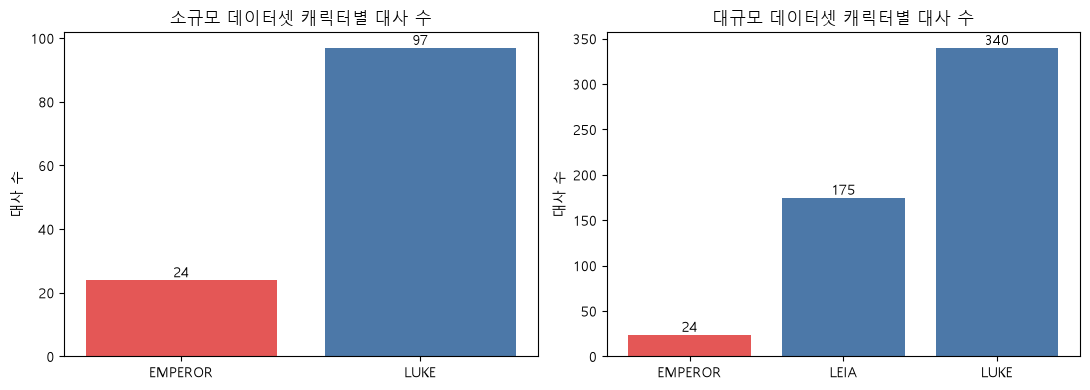

[소규모]


,,대사 수
Label,CharacterName_Clean,
Bad,EMPEROR,24
Good,LUKE,97


[대규모]


대사 수
Label CharacterName_Clean      
Bad   EMPEROR                24
Good  LEIA                  175
      LUKE                  340

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, df) in zip(axes, clean.items()):
    counts = df.groupby(["CharacterName_Clean", "Label"]).size().reset_index(name="n")
    bars = ax.bar(counts["CharacterName_Clean"], counts["n"], color=[COLOR[l] for l in counts["Label"]])
    ax.bar_label(bars)
    ax.set_title(f"{name} 데이터셋 캐릭터별 대사 수")
    ax.set_ylabel("대사 수")
plt.tight_layout()
plt.show()

for name, df in clean.items():
    print(f"[{name}]")
    display(df.groupby(["Label", "CharacterName_Clean"]).size().rename("대사 수").to_frame())

### 대사 길이 분포

대사가 매우 짧은 경우가 많으면 단어 정보가 부족해 분류가 어려워진다. 라벨별로 단어 수를 비교한다.

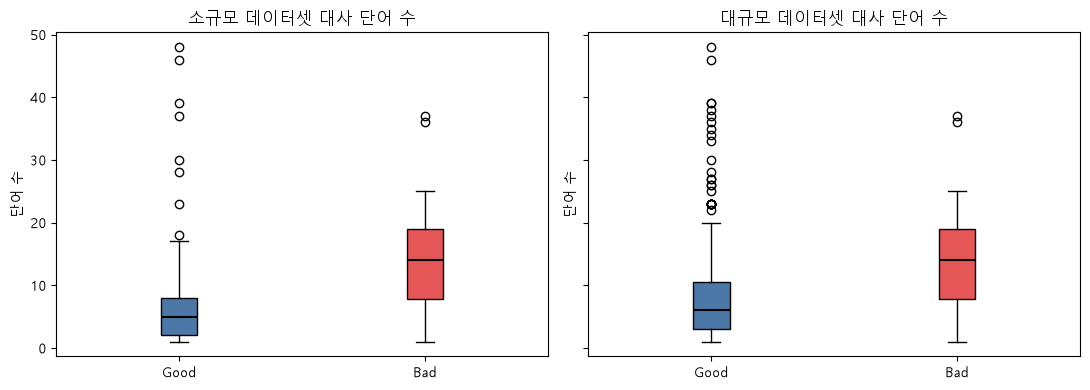

,데이터셋,라벨,평균,중앙값,최대,2단어 이하 비율(%)
0,소규모,Good,7.5,5.0,48,29.9
1,소규모,Bad,14.2,14.0,37,8.3
2,대규모,Good,8.1,6.0,48,13.6
3,대규모,Bad,14.2,14.0,37,8.3


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, df) in zip(axes, clean.items()):
    data = [df.loc[df["Label"] == l, "n_words"] for l in ["Good", "Bad"]]
    bp = ax.boxplot(data, patch_artist=True, medianprops={"color": "black", "linewidth": 1.5})
    ax.set_xticks([1, 2], ["Good", "Bad"])
    for patch, l in zip(bp["boxes"], ["Good", "Bad"]):
        patch.set_facecolor(COLOR[l])
    ax.set_title(f"{name} 데이터셋 대사 단어 수")
    ax.set_ylabel("단어 수")
plt.tight_layout()
plt.show()

rows = []
for name, df in clean.items():
    for label in ["Good", "Bad"]:
        w = df.loc[df["Label"] == label, "n_words"]
        rows.append({"데이터셋": name, "라벨": label, "평균": round(w.mean(), 1),
                     "중앙값": w.median(), "최대": w.max(),
                     "2단어 이하 비율(%)": round((w <= 2).mean() * 100, 1)})
display(pd.DataFrame(rows))

### 라벨별 자주 등장하는 단어

불용어를 제외하고 라벨별로 많이 쓰인 단어를 확인한다. 특정 단어가 한 클래스에만 몰려 있으면 모델이 캐릭터 고유 어휘를 학습할 가능성이 있다.

In [17]:
def top_words(texts, n=10):
    counter = Counter(
        w for t in texts for w in re.findall(r"[a-z']+", t.lower())
        if w not in ENGLISH_STOP_WORDS and len(w) > 1
    )
    return [f"{w} ({c})" for w, c in counter.most_common(n)]

for name, df in clean.items():
    table = {label: top_words(df.loc[df["Label"] == label, "Text"]) for label in ["Good", "Bad"]}
    print(f"[{name}] 상위 단어 (빈도)")
    display(pd.DataFrame(table, index=range(1, 11)))

[소규모] 상위 단어 (빈도)


,Good,Bad
1,i'm (9),yes (6)
2,know (8),navigator (3)
3,it's (6),force (3)
4,did (6),skywalker (3)
5,harry (5),young (3)
6,oh (5),visit (2)
7,don't (5),finished (2)
8,dollars (4),guild (2)
9,going (4),oh (2)
10,you're (4),things (2)


[대규모] 상위 단어 (빈도)


,Good,Bad
1,don't (42),yes (6)
2,know (35),navigator (3)
3,i'm (34),skywalker (3)
4,can't (21),force (3)
5,you're (19),young (3)
6,just (19),oh (2)
7,that's (18),things (2)
8,like (18),plans (2)
9,going (17),visit (2)
10,father (17),guild (2)


## 데이터 한계와 결과 해석 시 주의점

보고서의 한계 부분에 사용할 내용을 정리한다.

- **Bad 클래스의 표본이 매우 적다.** 학습과 평가 모두에서 Bad 대사가 몇 개뿐이므로, 대사 하나가 재현율을 크게 바꾼다. 따라서 단일 분할 결과만으로 결론을 내리지 않고 반복 교차검증의 평균과 표준편차를 함께 본다.
- **Bad는 사실상 EMPEROR 한 캐릭터뿐이다.** 모델이 '악한 대사'가 아니라 EMPEROR의 말투와 어휘를 학습했을 수 있다.
- **다른 영화의 대사가 섞여 있다.** 스타워즈 고유의 분류 성능이 아니라 영화별 어휘 차이를 학습했을 가능성이 있다.
- **대규모 데이터에서는 Good만 늘어나 Accuracy가 높아 보이는 착시가 생긴다.** 모든 대사를 Good으로 예측해도 Accuracy가 높게 나오므로 Bad Recall, Bad F1, Macro-F1을 함께 본다.
- **Bad 대사가 Good보다 훨씬 길다.** 대사 길이 자체가 분류 단서가 되어, 모델이 내용이 아니라 길이를 학습했을 수 있다.
- **자주 쓰이는 단어가 영화 어휘를 반영한다.** Bad 상위 단어에 듄 관련 단어(navigator, guild)가, Good 상위 단어에 스타워즈와 무관한 이름(harry)이 포함되어 있어 모델이 캐릭터의 선악이 아니라 영화별 어휘를 단서로 쓸 수 있다.
- **두 데이터셋이 독립적이지 않다.** 소규모 결과와 대규모 결과를 비교할 때 데이터 규모만의 효과로 해석하기 어렵다.
- **짧은 대사가 많다.** 단어 정보가 부족한 대사는 어떤 모델로도 구분하기 어렵다.
- 캐릭터 기준 라벨링은 과제용 규칙이므로 결과를 일반적인 감정 분석 성능으로 과장하지 않는다.

## 정제 데이터 저장

이후 실험에서 사용할 정제 데이터를 저장한다. `dup_group` 열은 데이터 분할에서 유사 중복을 같은 쪽에 두기 위해 사용한다.

In [18]:
clean["소규모"].to_csv(DATA_DIR / "starwars_100lines_clean.csv", index=False, encoding="utf-8-sig")
clean["대규모"].to_csv(DATA_DIR / "starwars_1000lines_clean.csv", index=False, encoding="utf-8-sig")
print("저장 완료:", "starwars_100lines_clean.csv,", "starwars_1000lines_clean.csv")

저장 완료: starwars_100lines_clean.csv, starwars_1000lines_clean.csv


## 실험 설계

### 실험 원칙

- **입력과 정답:** 입력은 정제된 대사(`Text`), 정답은 `Target`이다. Good = 1, Bad = 0이며 Bad(0)를 찾아내는 것이 핵심 목표이다.
- **기본 벡터화:** TF-IDF를 기본으로 사용한다. 대사가 짧고 I, you, the 같은 모든 캐릭터가 공통으로 쓰는 단어가 많아, 흔한 단어의 비중을 낮추는 TF-IDF가 단순 출현 횟수보다 유리할 것으로 예상하기 때문이다. 이 예상은 이후 CountVectorizer 비교 실험에서 검증한다.
- **평가 방법:** Bad 표본이 매우 적어 하나의 train/test 분할로는 결론을 내릴 수 없다. 따라서 층화 5-fold 교차검증을 서로 다른 random_state로 5번 반복하고, 각 fold 결과의 평균과 표준편차를 보고한다.
- **데이터 누출 방지:** 벡터화와 모델을 하나의 Pipeline으로 묶어 각 fold의 학습 데이터 안에서만 어휘 사전을 만든다. 또한 대소문자나 문장부호만 다른 유사 중복 대사(`dup_group`)가 학습과 검증에 나뉘지 않도록 그룹 단위로 분할한다.
- **중요 지표:** Accuracy는 참고용으로만 쓰고, Bad Precision, Bad Recall, Bad F1, Macro-F1과 혼동행렬로 판단한다.
- 이번 소규모 실험에서는 하이퍼파라미터를 조정하지 않고 기본에 가까운 값을 고정해서 사용한다. 조정은 이후 별도 단계에서 교차검증 안에서만 수행한다.

## 평가 프레임워크
### 라이브러리 불러오기

In [19]:
import warnings

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

### 입력 데이터 준비

In [20]:
data = {}
for name, df in clean.items():
    data[name] = {
        "X": df["Text"].reset_index(drop=True),
        "y": df["Target"].reset_index(drop=True),
        "groups": df["dup_group"].reset_index(drop=True),
    }

for name, d in data.items():
    print(f"[{name}] 대사 {len(d['y'])}개 / Good(1) {int((d['y'] == 1).sum())}개 / Bad(0) {int((d['y'] == 0).sum())}개")

[소규모] 대사 121개 / Good(1) 97개 / Bad(0) 24개
[대규모] 대사 539개 / Good(1) 515개 / Bad(0) 24개


### 교차검증 설정

층화 5-fold 분할을 5번 반복하므로 모델당 25개의 fold 결과가 나온다. 같은 데이터를 반복해서 쓰기 때문에 fold들이 완전히 독립적이지는 않으며, 표준편차는 결과가 분할에 따라 얼마나 흔들리는지 보여주는 지표로 해석한다.

In [21]:
N_SPLITS = 5
SEEDS = [RANDOM_STATE + i for i in range(5)]
METRICS = ["Accuracy", "Bad Precision", "Bad Recall", "Bad F1", "Macro-F1"]

print("반복에 사용하는 random_state:", SEEDS)

반복에 사용하는 random_state: [42, 43, 44, 45, 46]


### 평가 지표 함수

Bad(0) 클래스를 기준으로 Precision, Recall, F1을 계산하고, 두 클래스를 동등하게 보는 Macro-F1을 함께 계산한다.

In [22]:
def fold_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0], zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Bad Precision": p[0],
        "Bad Recall": r[0],
        "Bad F1": f[0],
        "Macro-F1": f1_score(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0),
    }


def run_cv(estimator, X, y, groups, seeds=SEEDS, n_splits=N_SPLITS):
    # 매 fold마다 모델을 새로 복제해 학습하고, 모든 대사에 대한 검증 예측(oof)도 저장
    rows, oof = [], {}
    for seed in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        pred = np.zeros(len(y), dtype=int)
        for k, (tr, te) in enumerate(cv.split(X, y, groups)):
            model = clone(estimator).fit(X.iloc[tr], y.iloc[tr])
            pred[te] = model.predict(X.iloc[te])
            rows.append({"seed": seed, "fold": k, **fold_metrics(y.iloc[te], pred[te])})
        oof[seed] = pred
    return {"folds": pd.DataFrame(rows), "oof": oof}


def run_experiment(estimators, dataset):
    d = data[dataset]
    return {name: run_cv(est, d["X"], d["y"], d["groups"]) for name, est in estimators.items()}


def summary_table(results):
    # 평균 ± 표준편차 표
    rows = {}
    for name, res in results.items():
        f = res["folds"][METRICS]
        rows[name] = {m: f"{f[m].mean():.3f} ± {f[m].std():.3f}" for m in METRICS}
    return pd.DataFrame(rows).T


def mean_table(results):
    return pd.DataFrame({name: res["folds"][METRICS].mean() for name, res in results.items()}).T

### 모델과 파이프라인 정의

다섯 모델을 모두 같은 벡터화와 같은 분할 조건에서 비교한다. 각 파이프라인은 `vec`(벡터화)와 `clf`(분류기) 두 단계로 이름을 붙였다.

- `class_weight`를 지원하지 않는 Multinomial NB는 `balanced`일 때 `fit_prior=False`(두 클래스의 사전확률을 같게 취급)로 대신 처리한다.
- HistGradientBoosting은 희소 행렬을 받지 못하므로 밀집 행렬로 바꾸는 단계(`dense`)를 추가한다.

In [23]:
def to_dense(X):
    return X.toarray()


def make_vectorizer(kind="tfidf"):
    if kind == "tfidf":
        return TfidfVectorizer(lowercase=True, ngram_range=(1, 1), min_df=1)
    return CountVectorizer(lowercase=True, ngram_range=(1, 1), min_df=1)


def build_models(vectorizer="tfidf", balanced=False):
    cw = "balanced" if balanced else None
    tag = "TF-IDF" if vectorizer == "tfidf" else "Count"
    clfs = {
        "Logistic Regression": LogisticRegression(C=1.0, solver="liblinear", class_weight=cw, max_iter=1000, random_state=RANDOM_STATE),
        "Linear SVC": LinearSVC(C=1.0, class_weight=cw, max_iter=5000, random_state=RANDOM_STATE),
        "Multinomial NB": MultinomialNB(alpha=1.0, fit_prior=not balanced),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=RANDOM_STATE, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingClassifier(class_weight=cw, random_state=RANDOM_STATE),
    }
    models = {}
    for name, clf in clfs.items():
        steps = [("vec", make_vectorizer(vectorizer))]
        if name == "HistGradientBoosting":
            steps.append(("dense", FunctionTransformer(to_dense, accept_sparse=True)))
        steps.append(("clf", clf))
        models[f"{tag} + {name}"] = Pipeline(steps)
    return models


models_default = build_models("tfidf", balanced=False)
for name, pipe in models_default.items():
    print(name, "->", [step for step, _ in pipe.steps])

TF-IDF + Logistic Regression -> ['vec', 'clf']
TF-IDF + Linear SVC -> ['vec', 'clf']
TF-IDF + Multinomial NB -> ['vec', 'clf']
TF-IDF + Random Forest -> ['vec', 'clf']
TF-IDF + HistGradientBoosting -> ['vec', 'dense', 'clf']


### 사용한 하이퍼파라미터

지금까지의 모든 실험은 아래 값으로 고정했다. 대부분 scikit-learn 기본값이며, 값을 조정하는 실험은 이후 별도 단계에서 교차검증 안에서만 수행한다.

| 구성 요소 | 파라미터 | 값 |
|---|---|---|
| TfidfVectorizer | lowercase, ngram_range, min_df, stop_words | True, (1, 1), 1, 사용 안 함 |
| Logistic Regression | C, solver, max_iter | 1.0, liblinear, 1000 |
| Linear SVC | C, max_iter | 1.0, 5000 |
| Multinomial NB | alpha, fit_prior | 1.0, True (balanced일 때 False) |
| Random Forest | n_estimators, max_depth | 300, 제한 없음 |
| HistGradientBoosting | learning_rate, max_iter | 0.1, 100 (기본값) |
| 불균형 대응 | class_weight | 기본 설정은 None, 보정 설정은 'balanced' |
| 교차검증 | 분할 방식 | StratifiedGroupKFold 5-fold, 5회 반복 |
| 공통 | random_state | 42 (반복마다 42부터 46) |

In [24]:
experiments = {}  # (데이터 규모, 벡터화, 불균형 대응) -> 교차검증 결과


def master_table():
    # 모든 실험 결과를 하나의 표로 모음: 최종 비교표의 재료
    rows = []
    for (dataset, vec, imb), results in experiments.items():
        for name, res in results.items():
            f = res["folds"][METRICS]
            if name.startswith("기준선"):
                vec_label, model_label = "-", name
                imb_label = "balanced" if "balanced" in name else "기본"
            else:
                vec_label, model_label = name.split(" + ")
                imb_label = imb
            rows.append({
                "데이터 규모": dataset, "벡터화": vec_label, "모델": model_label, "불균형 대응": imb_label,
                **{m: f[m].mean() for m in METRICS},
                "Bad Recall 표준편차": f["Bad Recall"].std(),
                "Macro-F1 표준편차": f["Macro-F1"].std(),
            })
    return pd.DataFrame(rows)


def print_reports(results, dataset):
    y = data[dataset]["y"]
    for name, res in results.items():
        print("=" * 70)
        print(name)
        print(classification_report(y, res["oof"][SEEDS[0]], labels=[0, 1],
                                    target_names=["Bad(0)", "Good(1)"], digits=3, zero_division=0))

### 분할마다 들어가는 Bad 대사 수 확인

Bad 표본이 적을 때 검증 fold 하나에 Bad 대사가 몇 개나 들어가는지 확인한다. 이 숫자가 작을수록 Recall이 크게 흔들린다.

In [25]:
rows = []
for name, d in data.items():
    counts = []
    for seed in SEEDS:
        cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
        for tr, te in cv.split(d["X"], d["y"], d["groups"]):
            counts.append(int((d["y"].iloc[te] == 0).sum()))
    rows.append({"데이터셋": name, "검증 fold당 Bad 대사 수 (최소)": min(counts),
                 "(평균)": round(float(np.mean(counts)), 1), "(최대)": max(counts),
                 "Bad 1개가 바꾸는 Recall (평균 기준, %p)": round(100 / np.mean(counts), 1)})
display(pd.DataFrame(rows))

,데이터셋,검증 fold당 Bad 대사 수 (최소),(평균),(최대),"Bad 1개가 바꾸는 Recall (평균 기준, %p)"
0,소규모,4,4.8,5,20.8
1,대규모,4,4.8,5,20.8


## 기준선 모델

모델의 점수가 의미 있는지 판단하려면 비교할 기준이 필요하다.

- **모두 Good으로 예측:** Bad를 하나도 찾지 못하는 모델. 이 모델의 Accuracy보다 높지 않으면 의미 있는 성능이 아니다.
- **대사 길이만 사용:** 단어 수와 글자 수만 입력으로 쓰는 로지스틱 회귀. 앞선 EDA에서 Bad 대사가 훨씬 길다는 것을 확인했으므로, 길이만으로 어디까지 분류되는지 확인한다. 이 점수가 다른 모델과 비슷하면 모델이 내용이 아니라 길이를 학습했을 가능성이 있다.

In [26]:
def length_features(texts):
    s = pd.Series(list(texts))
    return np.column_stack([np.log1p(s.str.split().str.len()), np.log1p(s.str.len())])


def build_baselines():
    return {
        "기준선: 모두 Good 예측": DummyClassifier(strategy="most_frequent"),
        "기준선: 길이만 사용": Pipeline([
            ("len", FunctionTransformer(length_features)),
            ("scale", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]),
        "기준선: 길이만 사용 (balanced)": Pipeline([
            ("len", FunctionTransformer(length_features)),
            ("scale", StandardScaler()),
            ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
        ]),
    }

## 소규모 데이터 실험
### 모델별 교차검증 결과

TF-IDF와 다섯 모델, 그리고 기준선을 같은 분할에서 평가한다. 표의 값은 25개 fold의 평균 ± 표준편차이다. Bad로 예측한 대사가 하나도 없는 fold는 Bad Precision을 0으로 계산했다.

In [27]:
results_small = run_experiment({**models_default, **build_baselines()}, "소규모")
display(summary_table(results_small))
experiments[("소규모", "TF-IDF", "기본")] = results_small

,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + Logistic Regression,0.802 ± 0.016,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.445 ± 0.005
TF-IDF + Linear SVC,0.854 ± 0.044,0.724 ± 0.334,0.370 ± 0.185,0.479 ± 0.218,0.697 ± 0.118
TF-IDF + Multinomial NB,0.802 ± 0.016,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.445 ± 0.005
TF-IDF + Random Forest,0.820 ± 0.031,0.320 ± 0.476,0.090 ± 0.144,0.138 ± 0.215,0.519 ± 0.114
TF-IDF + HistGradientBoosting,0.788 ± 0.030,0.040 ± 0.200,0.008 ± 0.040,0.013 ± 0.067,0.447 ± 0.037
기준선: 모두 Good 예측,0.802 ± 0.016,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.445 ± 0.005
기준선: 길이만 사용,0.768 ± 0.044,0.107 ± 0.254,0.048 ± 0.105,0.062 ± 0.136,0.464 ± 0.071
기준선: 길이만 사용 (balanced),0.709 ± 0.107,0.392 ± 0.131,0.736 ± 0.276,0.493 ± 0.162,0.641 ± 0.113


### 결과 시각화

막대는 평균, 오차 막대는 표준편차이다. 오차 막대가 길수록 분할에 따라 결과가 불안정하다는 뜻이다.

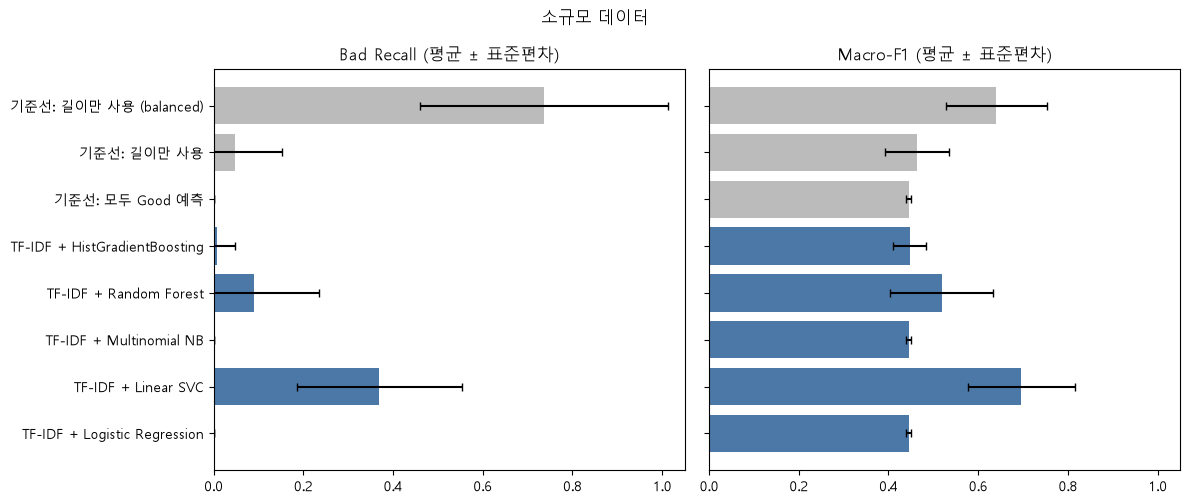

In [28]:
def plot_metrics(results, metrics=("Bad Recall", "Macro-F1"), title=""):
    names = list(results.keys())
    fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 0.45 * len(names) + 1.5), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), metrics):
        mean = [results[n]["folds"][m].mean() for n in names]
        std = [results[n]["folds"][m].std() for n in names]
        colors = ["#BBBBBB" if n.startswith("기준선") else "#4C78A8" for n in names]
        ax.barh(names, mean, xerr=std, color=colors, capsize=3)
        ax.set_xlim(0, 1.05)
        ax.set_title(f"{m} (평균 ± 표준편차)")
        ax.invert_yaxis()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_metrics(results_small, title="소규모 데이터")

### 혼동행렬

5번 반복한 검증 예측의 평균 개수이다. 행은 실제 라벨, 열은 예측 라벨이다. 왼쪽 위 칸이 Bad를 Bad로 맞힌 개수이다.

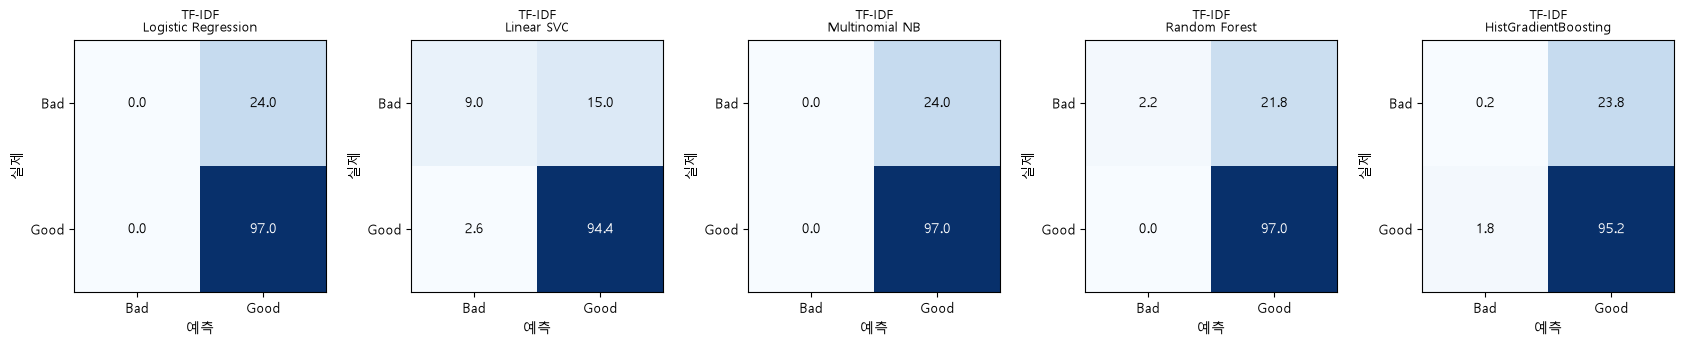

In [29]:
def plot_confusion(results, dataset, names=None):
    names = names or [n for n in results if not n.startswith("기준선")]
    y = data[dataset]["y"]
    fig, axes = plt.subplots(1, len(names), figsize=(3.4 * len(names), 3.3))
    for ax, n in zip(np.atleast_1d(axes), names):
        cms = [confusion_matrix(y, results[n]["oof"][s], labels=[0, 1]) for s in results[n]["oof"]]
        cm = np.mean(cms, axis=0)
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1], ["Bad", "Good"])
        ax.set_yticks([0, 1], ["Bad", "Good"])
        ax.set_xlabel("예측")
        ax.set_ylabel("실제")
        ax.set_title(n.replace(" + ", "\n"), fontsize=9)
    plt.tight_layout()
    plt.show()

plot_confusion(results_small, "소규모")

### 분류 리포트

첫 번째 반복(random_state = 42)에서 모든 대사를 한 번씩 검증에 사용한 예측을 모은 결과이다. 5번 반복 중 한 번의 결과이므로 위 표의 평균과 값이 다를 수 있다.

In [30]:
y_small = data["소규모"]["y"]
for name, res in results_small.items():
    print("=" * 70)
    print(name)
    print(classification_report(y_small, res["oof"][SEEDS[0]], labels=[0, 1],
                                target_names=["Bad(0)", "Good(1)"], digits=3, zero_division=0))

TF-IDF + Logistic Regression
              precision    recall  f1-score   support

      Bad(0)      0.000     0.000     0.000        24
     Good(1)      0.802     1.000     0.890        97

    accuracy                          0.802       121
   macro avg      0.401     0.500     0.445       121
weighted avg      0.643     0.802     0.713       121

TF-IDF + Linear SVC
              precision    recall  f1-score   support

      Bad(0)      0.846     0.458     0.595        24
     Good(1)      0.880     0.979     0.927        97

    accuracy                          0.876       121
   macro avg      0.863     0.719     0.761       121
weighted avg      0.873     0.876     0.861       121

TF-IDF + Multinomial NB
              precision    recall  f1-score   support

      Bad(0)      0.000     0.000     0.000        24
     Good(1)      0.802     1.000     0.890        97

    accuracy                          0.802       121
   macro avg      0.401     0.500     0.445       121
w

### 결과 해석

아래 내용은 이 실행 결과 기준이며, 같은 설정으로 다시 실행하면 같은 값이 나온다.

- **Logistic Regression과 Multinomial NB는 Bad를 하나도 예측하지 못했다.** 모든 대사를 Good으로 예측하는 기준선과 점수가 같으므로, 이 설정에서는 사실상 아무것도 학습하지 못한 것과 같다. Accuracy가 기준선 수준(약 80%)인 것도 이 때문이다.
- **Linear SVC가 기본 설정의 다섯 모델 중 Bad Recall, Bad F1, Macro-F1이 가장 높았다.** 다만 표준편차가 커서 분할에 따라 결과가 많이 달라진다.
- **Random Forest와 HistGradientBoosting은 Bad를 거의 찾지 못했다.** 몇 안 되는 Bad 표본이 고차원 희소 TF-IDF 공간에서 묻힌 것으로 보이며, 이는 계획서에서 짚은 트리 계열의 한계와 일치한다.
- **대사 길이만 쓴 balanced 기준선의 Bad Recall이 가장 높았고, Macro-F1도 Linear SVC와 표준편차 범위 안에서 비슷했다.** 길이는 Bad를 가르는 강한 지름길이며, 단어를 쓰는 모델이 길이 이상의 정보를 얼마나 학습했는지는 불확실하다.
- **공정한 비교는 아직 아니다.** 다섯 모델은 클래스 가중치 없이, 길이 기준선(balanced)은 가중치를 준 상태이다. 이어지는 부분에서 모든 모델에 `class_weight='balanced'`를 적용해 같은 조건으로 다시 비교한다.
- Bad 대사가 검증 fold당 4~5개뿐이어서 Recall은 한 개당 약 20%p씩 움직인다. 큰 표준편차는 모델이 불안정해서라기보다 표본이 적기 때문이기도 하다.

### 클래스 가중치 적용 결과 (소규모)

같은 데이터와 같은 분할에서 다섯 모델에 `class_weight='balanced'`를 적용한다. Multinomial NB는 `class_weight`가 없으므로 `fit_prior=False`로 대신한다.

,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + Logistic Regression,0.853 ± 0.052,0.673 ± 0.226,0.590 ± 0.191,0.607 ± 0.162,0.758 ± 0.094
TF-IDF + Linear SVC,0.871 ± 0.047,0.773 ± 0.245,0.546 ± 0.207,0.610 ± 0.180,0.766 ± 0.100
TF-IDF + Multinomial NB,0.786 ± 0.064,0.492 ± 0.126,0.724 ± 0.179,0.574 ± 0.113,0.714 ± 0.075
TF-IDF + Random Forest,0.856 ± 0.059,0.643 ± 0.439,0.346 ± 0.269,0.433 ± 0.310,0.675 ± 0.169
TF-IDF + HistGradientBoosting,0.706 ± 0.078,0.325 ± 0.163,0.452 ± 0.254,0.365 ± 0.176,0.586 ± 0.108


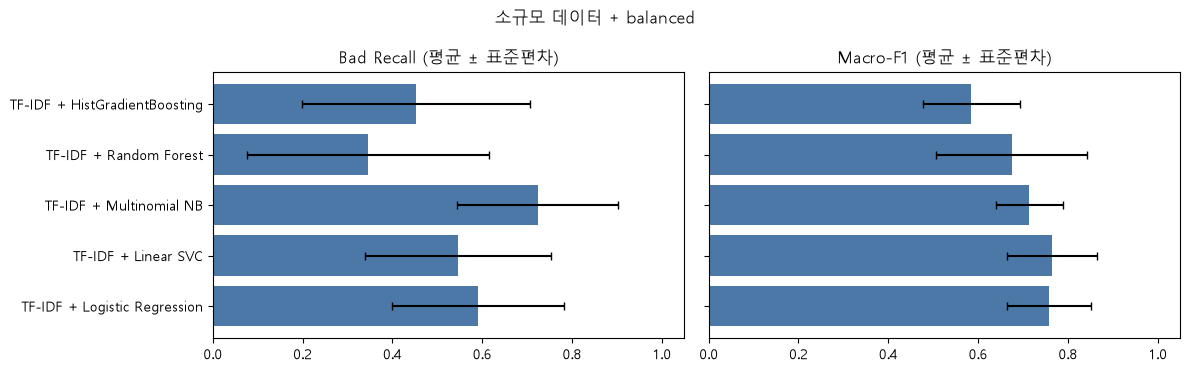

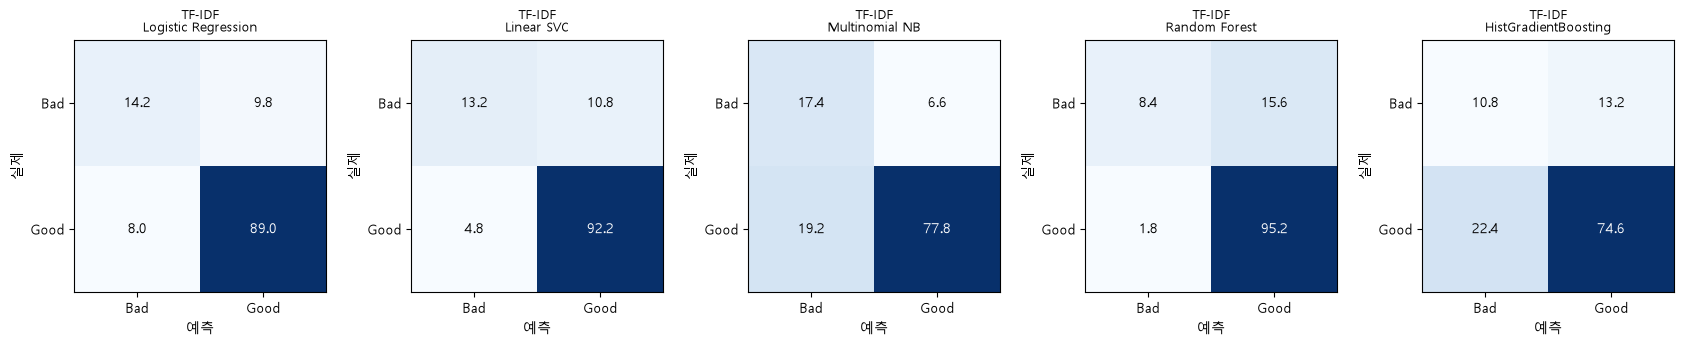

In [31]:
models_balanced = build_models("tfidf", balanced=True)
results_small_bal = run_experiment(models_balanced, "소규모")
experiments[("소규모", "TF-IDF", "balanced")] = results_small_bal

display(summary_table(results_small_bal))
plot_metrics(results_small_bal, title="소규모 데이터 + balanced")
plot_confusion(results_small_bal, "소규모")

## 대규모 데이터 실험

소규모 실험과 같은 전처리, 같은 분할 방식, 같은 지표를 사용한다.

### 기본 설정 결과

,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + Logistic Regression,0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
TF-IDF + Linear SVC,0.957 ± 0.005,0.200 ± 0.408,0.042 ± 0.086,0.069 ± 0.142,0.524 ± 0.072
TF-IDF + Multinomial NB,0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
TF-IDF + Random Forest,0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
TF-IDF + HistGradientBoosting,0.951 ± 0.008,0.040 ± 0.200,0.008 ± 0.040,0.013 ± 0.067,0.494 ± 0.034
기준선: 모두 Good 예측,0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
기준선: 길이만 사용,0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
기준선: 길이만 사용 (balanced),0.667 ± 0.046,0.086 ± 0.021,0.668 ± 0.188,0.151 ± 0.036,0.472 ± 0.031


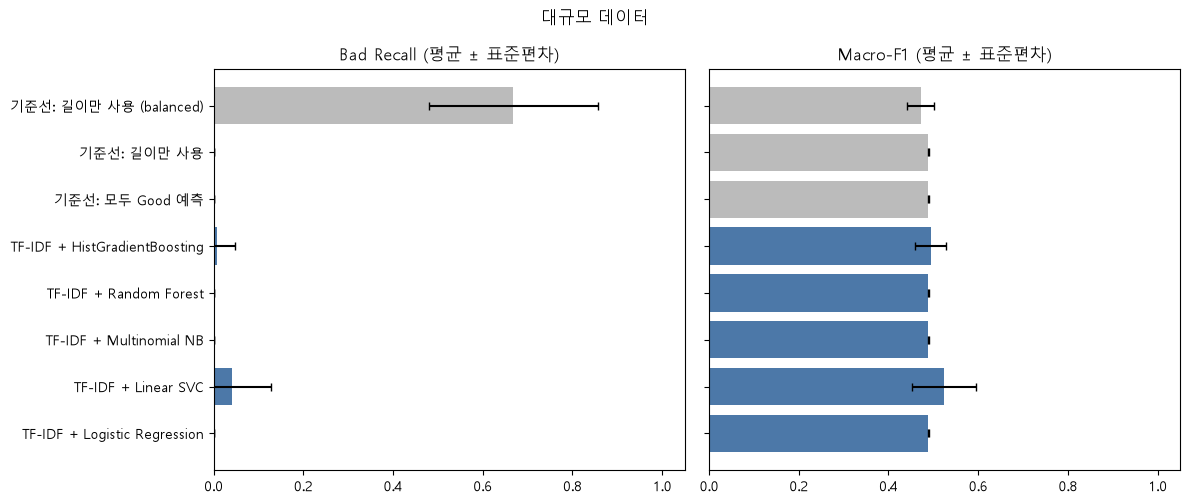

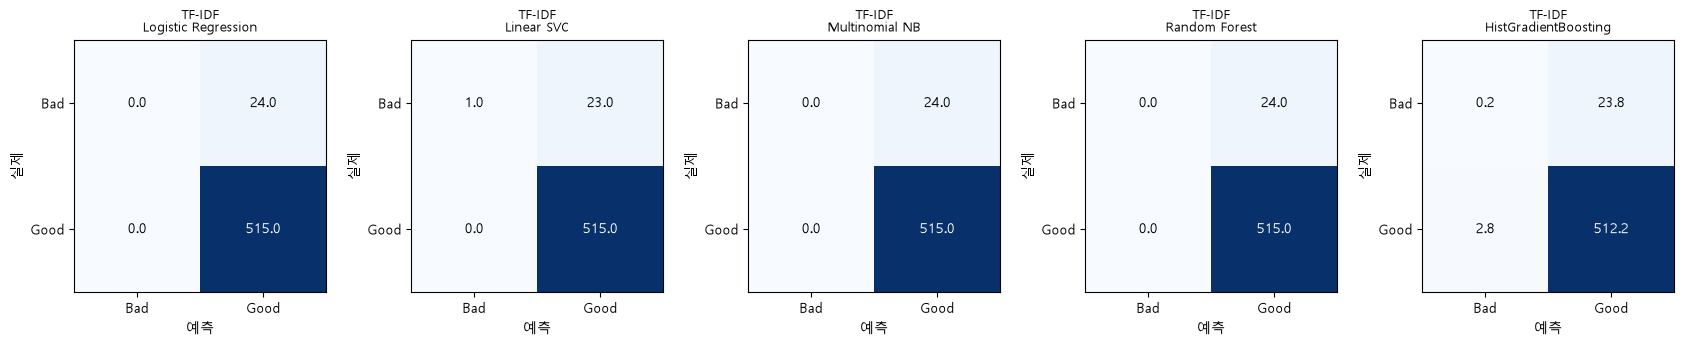

In [32]:
results_large = run_experiment({**models_default, **build_baselines()}, "대규모")
experiments[("대규모", "TF-IDF", "기본")] = results_large

display(summary_table(results_large))
plot_metrics(results_large, title="대규모 데이터")
plot_confusion(results_large, "대규모")

### 클래스 가중치 적용 결과

,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + Logistic Regression,0.945 ± 0.016,0.422 ± 0.248,0.376 ± 0.237,0.357 ± 0.171,0.664 ± 0.087
TF-IDF + Linear SVC,0.952 ± 0.014,0.493 ± 0.293,0.324 ± 0.216,0.356 ± 0.191,0.666 ± 0.098
TF-IDF + Multinomial NB,0.891 ± 0.034,0.101 ± 0.127,0.156 ± 0.178,0.120 ± 0.143,0.531 ± 0.078
TF-IDF + Random Forest,0.954 ± 0.006,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.488 ± 0.001
TF-IDF + HistGradientBoosting,0.915 ± 0.023,0.041 ± 0.097,0.040 ± 0.082,0.037 ± 0.081,0.496 ± 0.041


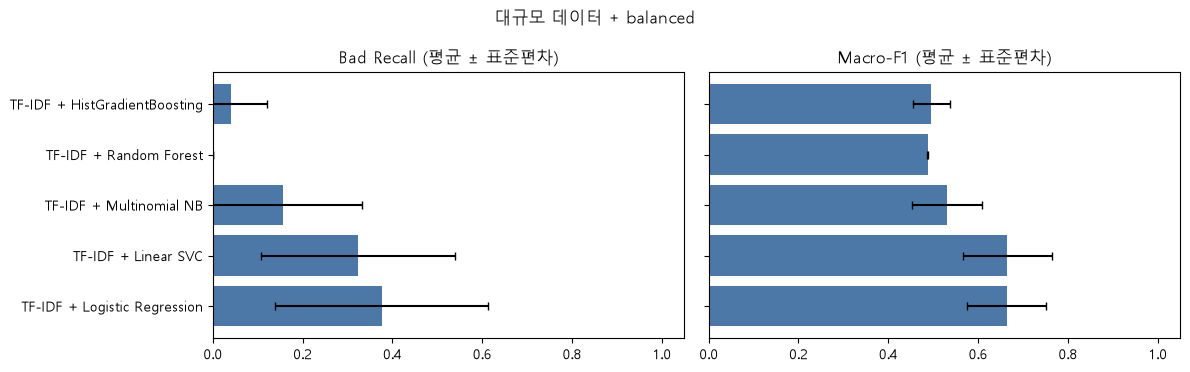

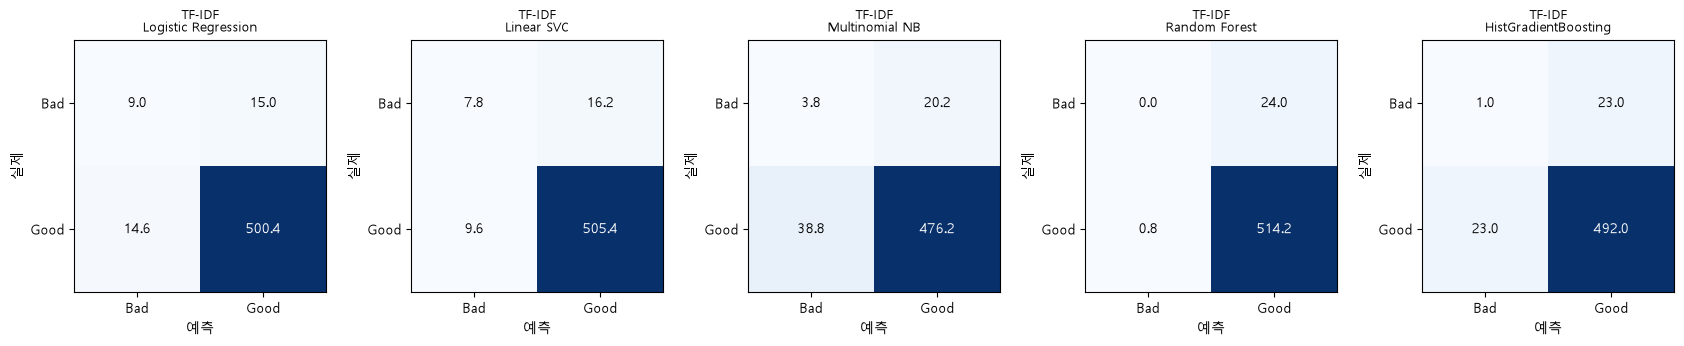

In [33]:
results_large_bal = run_experiment(models_balanced, "대규모")
experiments[("대규모", "TF-IDF", "balanced")] = results_large_bal

display(summary_table(results_large_bal))
plot_metrics(results_large_bal, title="대규모 데이터 + balanced")
plot_confusion(results_large_bal, "대규모")

### 분류 리포트

첫 번째 반복(random_state = 42)의 검증 예측 기준이다.

In [34]:
print("##### 대규모 / 기본 설정")
print_reports({k: v for k, v in results_large.items() if not k.startswith("기준선")}, "대규모")
print("\n##### 대규모 / balanced")
print_reports(results_large_bal, "대규모")

##### 대규모 / 기본 설정
TF-IDF + Logistic Regression
              precision    recall  f1-score   support

      Bad(0)      0.000     0.000     0.000        24
     Good(1)      0.955     1.000     0.977       515

    accuracy                          0.955       539
   macro avg      0.478     0.500     0.489       539
weighted avg      0.913     0.955     0.934       539

TF-IDF + Linear SVC
              precision    recall  f1-score   support

      Bad(0)      1.000     0.125     0.222        24
     Good(1)      0.961     1.000     0.980       515

    accuracy                          0.961       539
   macro avg      0.980     0.562     0.601       539
weighted avg      0.963     0.961     0.946       539

TF-IDF + Multinomial NB
              precision    recall  f1-score   support

      Bad(0)      0.000     0.000     0.000        24
     Good(1)      0.955     1.000     0.977       515

    accuracy                          0.955       539
   macro avg      0.478     0.500    

## 기본 설정과 balanced 비교

같은 모델에서 `class_weight='balanced'`가 Bad(0) 클래스의 Precision, Recall에 어떤 영향을 주는지 데이터셋별로 비교한다. 값은 25개 fold의 평균이다.

In [35]:
def compare_default_balanced(res_default, res_bal):
    d = mean_table({k: v for k, v in res_default.items() if not k.startswith("기준선")})
    b = mean_table(res_bal)
    d.index = [i.replace("TF-IDF + ", "") for i in d.index]
    b.index = [i.replace("TF-IDF + ", "") for i in b.index]
    out = pd.concat({"기본": d, "balanced": b}, axis=1).swaplevel(axis=1)
    order = [(m, s) for m in METRICS for s in ["기본", "balanced"]]
    return out[order].round(3)

for dataset, rd, rb in [("소규모", results_small, results_small_bal), ("대규모", results_large, results_large_bal)]:
    print(f"[{dataset}] 기본 vs balanced (평균)")
    display(compare_default_balanced(rd, rb))

[소규모] 기본 vs balanced (평균)


Accuracy          Bad Precision          Bad Recall          Bad F1          Macro-F1         
                           기본 balanced            기본 balanced         기본 balanced     기본 balanced       기본 balanced
Logistic Regression     0.802    0.853         0.000    0.673      0.000    0.590  0.000    0.607    0.445    0.758
Linear SVC              0.854    0.871         0.724    0.773      0.370    0.546  0.479    0.610    0.697    0.766
Multinomial NB          0.802    0.786         0.000    0.492      0.000    0.724  0.000    0.574    0.445    0.714
Random Forest           0.820    0.856         0.320    0.643      0.090    0.346  0.138    0.433    0.519    0.675
HistGradientBoosting    0.788    0.706         0.040    0.325      0.008    0.452  0.013    0.365    0.447    0.586

[대규모] 기본 vs balanced (평균)


Accuracy          Bad Precision          Bad Recall          Bad F1          Macro-F1         
                           기본 balanced            기본 balanced         기본 balanced     기본 balanced       기본 balanced
Logistic Regression     0.955    0.945          0.00    0.422      0.000    0.376  0.000    0.357    0.489    0.664
Linear SVC              0.957    0.952          0.20    0.493      0.042    0.324  0.069    0.356    0.524    0.666
Multinomial NB          0.955    0.891          0.00    0.101      0.000    0.156  0.000    0.120    0.489    0.531
Random Forest           0.955    0.954          0.00    0.000      0.000    0.000  0.000    0.000    0.489    0.488
HistGradientBoosting    0.951    0.915          0.04    0.041      0.008    0.040  0.013    0.037    0.494    0.496

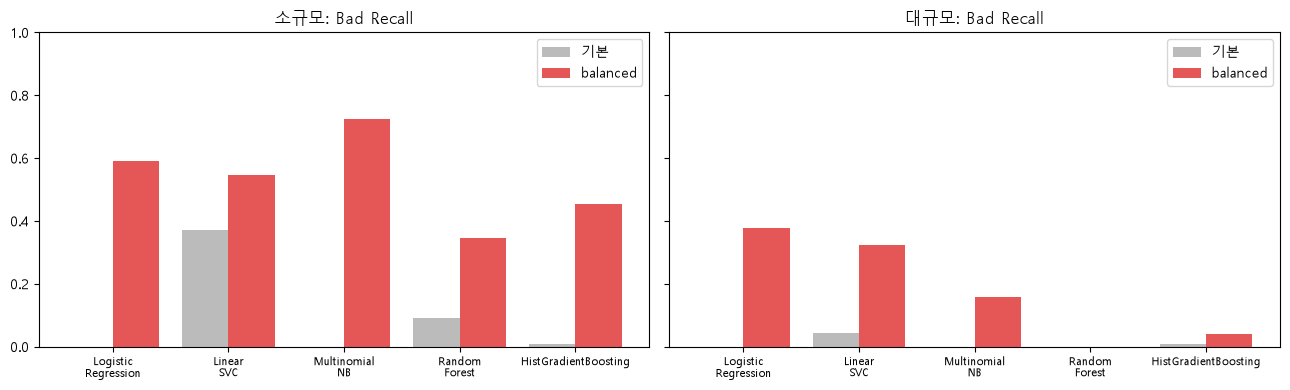

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (dataset, rd, rb) in zip(axes, [("소규모", results_small, results_small_bal), ("대규모", results_large, results_large_bal)]):
    d = compare_default_balanced(rd, rb)["Bad Recall"]
    x = np.arange(len(d))
    ax.bar(x - 0.2, d["기본"], 0.4, label="기본", color="#BBBBBB")
    ax.bar(x + 0.2, d["balanced"], 0.4, label="balanced", color="#E45756")
    ax.set_xticks(x, [n.replace(" ", "\n", 1) for n in d.index], fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(f"{dataset}: Bad Recall")
    ax.legend()
plt.tight_layout()
plt.show()

## 데이터 규모에 따른 변화

데이터를 늘렸을 때 Accuracy와 Bad Recall이 어떻게 달라지는지 기본 설정 모델로 비교한다. 점선은 모든 대사를 Good으로 예측했을 때의 Accuracy(다수 클래스 기준선)이다.

,소규모 Accuracy,소규모 Bad Recall,소규모 Macro-F1,대규모 Accuracy,대규모 Bad Recall,대규모 Macro-F1
TF-IDF + Logistic Regression,0.802,0.000,0.445,0.955,0.000,0.489
TF-IDF + Linear SVC,0.854,0.370,0.697,0.957,0.042,0.524
TF-IDF + Multinomial NB,0.802,0.000,0.445,0.955,0.000,0.489
TF-IDF + Random Forest,0.820,0.090,0.519,0.955,0.000,0.489
TF-IDF + HistGradientBoosting,0.788,0.008,0.447,0.951,0.008,0.494
기준선: 모두 Good 예측,0.802,0.000,0.445,0.955,0.000,0.489


다수 클래스 기준선 Accuracy: {'소규모': np.float64(0.802), '대규모': np.float64(0.955)}


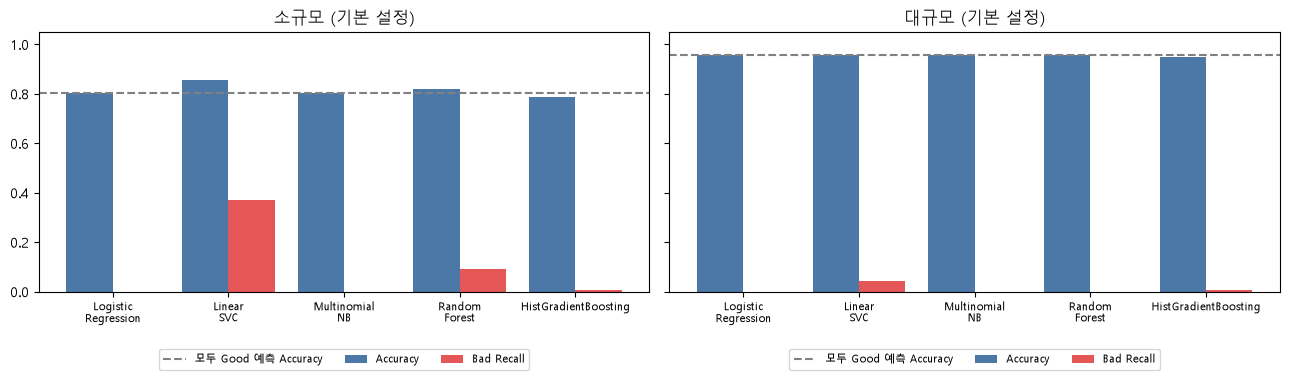

In [37]:
rows = {}
for name in [n for n in results_small if not n.startswith("기준선")] + ["기준선: 모두 Good 예측"]:
    rows[name] = {}
    for dataset, res in [("소규모", results_small), ("대규모", results_large)]:
        f = res[name]["folds"]
        rows[name][f"{dataset} Accuracy"] = f["Accuracy"].mean()
        rows[name][f"{dataset} Bad Recall"] = f["Bad Recall"].mean()
        rows[name][f"{dataset} Macro-F1"] = f["Macro-F1"].mean()
scale_table = pd.DataFrame(rows).T
display(scale_table.round(3))

majority = {n: max(d["y"].mean(), 1 - d["y"].mean()) for n, d in data.items()}
print("다수 클래스 기준선 Accuracy:", {k: round(v, 3) for k, v in majority.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
names = [n for n in scale_table.index if not n.startswith("기준선")]
for ax, dataset in zip(axes, ["소규모", "대규모"]):
    x = np.arange(len(names))
    ax.bar(x - 0.2, scale_table.loc[names, f"{dataset} Accuracy"], 0.4, label="Accuracy", color="#4C78A8")
    ax.bar(x + 0.2, scale_table.loc[names, f"{dataset} Bad Recall"], 0.4, label="Bad Recall", color="#E45756")
    ax.axhline(majority[dataset], color="gray", linestyle="--", label="모두 Good 예측 Accuracy")
    ax.set_xticks(x, [n.replace("TF-IDF + ", "").replace(" ", "\n", 1) for n in names], fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{dataset} (기본 설정)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

### 결과 해석

아래 내용은 이 실행 결과 기준이며, 같은 설정으로 다시 실행하면 같은 값이 나온다.

- **대규모 데이터의 기본 설정 모델은 모두 다수 클래스 기준선과 다르지 않았다.** Accuracy는 0.95 안팎으로 모든 대사를 Good으로 예측했을 때(약 0.955)와 같고, Bad Recall은 거의 0이다. Accuracy가 높아 보이는 것은 Good 대사만 늘어난 데이터 구성 때문이며 성능 향상이 아니다. 이 경우 Accuracy와 Bad Recall은 정반대의 결론을 준다.
- **`class_weight='balanced'`는 Bad Recall을 크게 올렸다.** 대규모 데이터에서 Logistic Regression은 0.000에서 약 0.38로, Linear SVC는 약 0.04에서 약 0.32로 올랐다. 대신 Accuracy가 조금 내려가거나(Multinomial NB는 0.955에서 약 0.89) Precision이 낮은 경우가 있어, Bad를 더 많이 찾는 대신 Good을 Bad로 잘못 부르는 오류도 늘어난다.
- **Random Forest와 HistGradientBoosting은 balanced를 적용해도 Bad를 거의 찾지 못했다.** 희소하고 고차원인 TF-IDF 특징에서 24개뿐인 Bad 표본으로는 트리 분할이 잘 일어나지 않는 것으로 보인다.
- **데이터를 늘렸더니 오히려 성능이 낮아졌다.** balanced 적용 시 Macro-F1이 Logistic Regression은 약 0.76에서 약 0.66으로, Linear SVC는 약 0.77에서 약 0.67로 내려갔다. Bad는 24개로 그대로이고 Good만 늘어 불균형이 약 4:1에서 약 21.5:1이 된 것이 가장 유력한 이유이며, LEIA가 추가되어 Good 대사의 구성이 달라진 점도 영향을 주었을 수 있다. 표준편차는 줄지 않아 결과가 더 안정적이 되지도 않았다.
- **Logistic Regression과 Linear SVC는 거의 비슷하다.** 두 모델의 Macro-F1 차이는 표준편차보다 훨씬 작아서 어느 쪽이 낫다고 단정하기 어렵다. 최종 모델 선정은 Bad Recall, Bad F1, 안정성을 함께 보고 이후 단계에서 한다.
- **Multinomial NB는 소규모에서 Bad Recall이 가장 높았지만 Precision이 낮았고, 대규모에서는 크게 떨어졌다.**
- **대사 길이만 쓴 기준선은 대규모에서 힘을 잃었다.** balanced 길이 기준선의 Bad Precision이 약 0.09까지 떨어져 Macro-F1이 다수 클래스 기준선보다도 낮았다. 대규모에는 긴 Good 대사가 많아 길이만으로는 Bad를 구분하기 어렵기 때문으로 보인다.

## TF-IDF 계산 원리 확인

교수님이 제공한 엑셀 파일(`tfidf_excel_formulas_model.xlsx`)의 4개 문서 예제를 파이썬으로 다시 계산해, 엑셀 수식과 scikit-learn의 `TfidfVectorizer`가 같은 값을 내는지 확인한다.

| 단계 | 엑셀 수식 | 의미 |
|---|---|---|
| TF | `CountVectorizer` 시트 값 | 문서 안 단어 출현 횟수 |
| DF | `=COUNTIF(범위, ">0")` | 그 단어가 등장한 문서 수 |
| IDF | `=LN((4+1)/(DF+1))+1` | 여러 문서에 흔한 단어일수록 작은 값 (smooth_idf) |
| TF-IDF | `=TF*IDF` | 단어 중요도 |
| 정규화 | `=값/L2노름` | 각 문서 벡터의 길이를 1로 맞춤 |

In [38]:
toy_docs = ["파이썬 머신러닝 데이터 분석", "머신러닝 딥러닝 인공지능 분석", "파이썬 데이터 분석 시각화", "인공지능 머신러닝 파이썬 수집"]

cv_toy = CountVectorizer()
counts = cv_toy.fit_transform(toy_docs).toarray()          # TF
terms = cv_toy.get_feature_names_out()
n_docs = len(toy_docs)
df_count = (counts > 0).sum(axis=0)                        # DF: COUNTIF
idf = np.log((n_docs + 1) / (df_count + 1)) + 1            # IDF: LN((N+1)/(DF+1))+1
tfidf_raw = counts * idf                                   # TF x IDF
l2 = np.sqrt((tfidf_raw ** 2).sum(axis=1, keepdims=True))  # L2 노름
tfidf_manual = tfidf_raw / l2                              # L2 정규화

tfidf_sklearn = TfidfVectorizer().fit_transform(toy_docs).toarray()

display(pd.DataFrame(counts, columns=terms, index=[f"문서 {i + 1}" for i in range(n_docs)]))
display(pd.DataFrame({"DF": df_count, "IDF": idf.round(4)}, index=terms).T)
display(pd.DataFrame(tfidf_manual, columns=terms, index=[f"문서 {i + 1}" for i in range(n_docs)]).round(4))
print("직접 계산과 scikit-learn TfidfVectorizer의 최대 차이:", float(np.abs(tfidf_manual - tfidf_sklearn).max()))

,데이터,딥러닝,머신러닝,분석,수집,시각화,인공지능,파이썬
문서 1,1,0,1,1,0,0,0,1
문서 2,0,1,1,1,0,0,1,0
문서 3,1,0,0,1,0,1,0,1
문서 4,0,0,1,0,1,0,1,1


,데이터,딥러닝,머신러닝,분석,수집,시각화,인공지능,파이썬
DF,2.0000,1.0000,3.0000,3.0000,1.0000,1.0000,2.0000,3.0000
IDF,1.5108,1.9163,1.2231,1.2231,1.9163,1.9163,1.5108,1.2231


,데이터,딥러닝,머신러닝,분석,수집,시각화,인공지능,파이썬
문서 1,0.5806,0.0000,0.4701,0.4701,0.0000,0.0000,0.0000,0.4701
문서 2,0.0000,0.6407,0.4089,0.4089,0.0000,0.0000,0.5051,0.0000
문서 3,0.5051,0.0000,0.0000,0.4089,0.0000,0.6407,0.0000,0.4089
문서 4,0.0000,0.0000,0.4089,0.0000,0.6407,0.0000,0.5051,0.4089


직접 계산과 scikit-learn TfidfVectorizer의 최대 차이: 0.0


엑셀 수식, 직접 계산, scikit-learn의 결과가 같다. 참고로 scikit-learn은 단어를 가나다순으로 정렬하므로 '수집'이 '시각화'보다 앞에 오며, 엑셀 시트와 열 순서만 다르고 값은 같다.

이 계산은 이 프로젝트의 Count와 TF-IDF 비교를 설명해 준다. 여러 문서에 자주 나오는 단어(영화 대사에서는 I, you, the 같은 단어)는 DF가 커서 IDF가 작아지고, 일부 문서에만 나오는 단어는 IDF가 커져 중요하게 취급된다. 또한 L2 정규화 때문에 TF-IDF는 대사가 길어도 벡터 길이가 일정하지만, Count는 단어가 많을수록 값이 커진다.

## 벡터화 방식 비교 (Count vs TF-IDF)

같은 데이터, 같은 분할, 같은 모델 조건에서 CountVectorizer와 TfidfVectorizer를 비교한다. 클래스 불균형이 있어 기본 설정에서는 대부분의 모델이 Bad를 찾지 못하므로, 비교는 `class_weight='balanced'` 설정에서 한다.

### 같은 분할에서의 비교

In [39]:
models_count_bal = build_models("count", balanced=True)
results_small_count = run_experiment(models_count_bal, "소규모")
results_large_count = run_experiment(models_count_bal, "대규모")
experiments[("소규모", "Count", "balanced")] = results_small_count
experiments[("대규모", "Count", "balanced")] = results_large_count


def paired_table(res_a, res_b, label_a, label_b, strip_a="", strip_b="", metric="Macro-F1"):
    # 같은 (seed, fold) 끼리 짝지어 평균 차이를 계산
    rows = {}
    for na in res_a:
        key = na.replace(strip_a, "")
        nb_ = [n for n in res_b if n.replace(strip_b, "") == key]
        if not nb_:
            continue
        a, b = res_a[na]["folds"], res_b[nb_[0]]["folds"]
        m = a.merge(b, on=["seed", "fold"], suffixes=("_a", "_b"))
        diff = m[f"{metric}_a"] - m[f"{metric}_b"]
        rows[key] = {f"{metric} {label_a}": m[f"{metric}_a"].mean(), f"{metric} {label_b}": m[f"{metric}_b"].mean(),
                     f"차이 ({label_a} - {label_b})": diff.mean(), "차이의 표준편차": diff.std(),
                     f"{label_a} 우세 fold 수": int((diff > 0).sum()), f"{label_b} 우세 fold 수": int((diff < 0).sum()),
                     "동점 fold 수": int((diff == 0).sum())}
    return pd.DataFrame(rows).T


for dataset, r_tf, r_ct in [("소규모", results_small_bal, results_small_count), ("대규모", results_large_bal, results_large_count)]:
    print(f"[{dataset}] Macro-F1: TF-IDF vs Count (balanced)")
    display(paired_table(r_tf, r_ct, "TF-IDF", "Count", "TF-IDF + ", "Count + ").round(3))
    print(f"[{dataset}] Bad Recall: TF-IDF vs Count (balanced)")
    display(paired_table(r_tf, r_ct, "TF-IDF", "Count", "TF-IDF + ", "Count + ", metric="Bad Recall").round(3))

[소규모] Macro-F1: TF-IDF vs Count (balanced)


,Macro-F1 TF-IDF,Macro-F1 Count,차이 (TF-IDF - Count),차이의 표준편차,TF-IDF 우세 fold 수,Count 우세 fold 수,동점 fold 수
Logistic Regression,0.758,0.708,0.050,0.136,14.0,6.0,5.0
Linear SVC,0.766,0.676,0.089,0.114,18.0,2.0,5.0
Multinomial NB,0.714,0.664,0.050,0.069,17.0,3.0,5.0
Random Forest,0.675,0.717,-0.042,0.077,1.0,7.0,17.0
HistGradientBoosting,0.586,0.590,-0.004,0.019,0.0,2.0,23.0


[소규모] Bad Recall: TF-IDF vs Count (balanced)


,Bad Recall TF-IDF,Bad Recall Count,차이 (TF-IDF - Count),차이의 표준편차,TF-IDF 우세 fold 수,Count 우세 fold 수,동점 fold 수
Logistic Regression,0.590,0.434,0.156,0.252,14.0,4.0,7.0
Linear SVC,0.546,0.368,0.178,0.216,14.0,1.0,10.0
Multinomial NB,0.724,0.750,-0.026,0.109,2.0,5.0,18.0
Random Forest,0.346,0.410,-0.064,0.106,0.0,7.0,18.0
HistGradientBoosting,0.452,0.462,-0.010,0.050,0.0,1.0,24.0


[대규모] Macro-F1: TF-IDF vs Count (balanced)


,Macro-F1 TF-IDF,Macro-F1 Count,차이 (TF-IDF - Count),차이의 표준편차,TF-IDF 우세 fold 수,Count 우세 fold 수,동점 fold 수
Logistic Regression,0.664,0.634,0.030,0.089,13.0,7.0,5.0
Linear SVC,0.666,0.628,0.037,0.111,14.0,7.0,4.0
Multinomial NB,0.531,0.547,-0.016,0.047,15.0,10.0,0.0
Random Forest,0.488,0.589,-0.100,0.101,4.0,14.0,7.0
HistGradientBoosting,0.496,0.524,-0.028,0.062,12.0,13.0,0.0


[대규모] Bad Recall: TF-IDF vs Count (balanced)


,Bad Recall TF-IDF,Bad Recall Count,차이 (TF-IDF - Count),차이의 표준편차,TF-IDF 우세 fold 수,Count 우세 fold 수,동점 fold 수
Logistic Regression,0.376,0.294,0.082,0.201,10.0,3.0,12.0
Linear SVC,0.324,0.260,0.064,0.206,11.0,5.0,9.0
Multinomial NB,0.156,0.250,-0.094,0.124,0.0,10.0,15.0
Random Forest,0.000,0.140,-0.140,0.143,0.0,14.0,11.0
HistGradientBoosting,0.040,0.186,-0.146,0.179,1.0,13.0,11.0


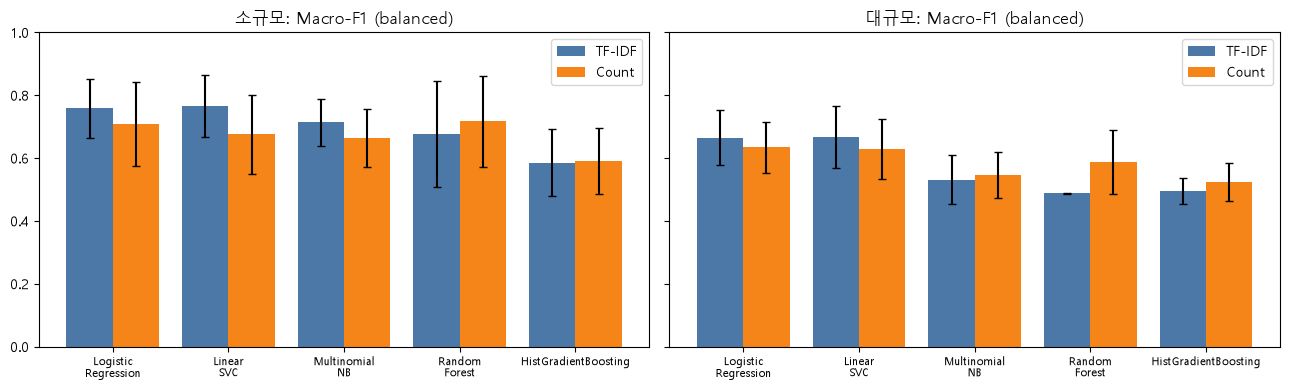

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (dataset, r_tf, r_ct) in zip(axes, [("소규모", results_small_bal, results_small_count), ("대규모", results_large_bal, results_large_count)]):
    names = [n.replace("TF-IDF + ", "") for n in r_tf]
    x = np.arange(len(names))
    tf = [r_tf[f"TF-IDF + {n}"]["folds"]["Macro-F1"] for n in names]
    ct = [r_ct[f"Count + {n}"]["folds"]["Macro-F1"] for n in names]
    ax.bar(x - 0.2, [v.mean() for v in tf], 0.4, yerr=[v.std() for v in tf], capsize=3, label="TF-IDF", color="#4C78A8")
    ax.bar(x + 0.2, [v.mean() for v in ct], 0.4, yerr=[v.std() for v in ct], capsize=3, label="Count", color="#F58518")
    ax.set_xticks(x, [n.replace(" ", "\n", 1) for n in names], fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(f"{dataset}: Macro-F1 (balanced)")
    ax.legend()
plt.tight_layout()
plt.show()

### 결과 해석

- **선형 모델(Logistic Regression, Linear SVC)에서는 TF-IDF가 Count보다 일관되게 높았다.** Macro-F1이 소규모에서 각각 0.758 대 0.708, 0.766 대 0.676, 대규모에서 0.664 대 0.634, 0.666 대 0.628이다. 소규모의 Linear SVC는 25개 fold 중 18개에서 TF-IDF가 이겼고 Count가 이긴 fold는 2개뿐이었다.
- **다만 차이는 fold 간 표준편차(약 0.09~0.14)보다 작아 확실한 우위는 아니다.** 방향은 일관되지만 크기는 작다고 보는 것이 맞다.
- **Naive Bayes, Random Forest, HistGradientBoosting은 대규모에서 Count가 조금 높았지만**, 이 모델들은 모두 기준선 수준의 성능이라 비교에 의미를 두기 어렵다.
- **데이터 특성으로 설명하면:** 대사는 짧고 I, you, the처럼 모든 캐릭터가 쓰는 단어가 많다. Count는 이런 단어를 똑같이 세지만 TF-IDF는 흔한 단어의 비중을 낮춘다. 또한 L2 정규화로 대사 길이의 영향이 줄어든다.

## 하이퍼파라미터 탐색

Bad 표본이 24개뿐이라 큰 탐색은 교차검증 점수에 과적합되기 쉽다. 그래서 가장 유력한 두 모델(Logistic Regression, Linear SVC, 둘 다 balanced)에 대해서만 작은 격자를 탐색한다.

### 탐색 방법

- **중첩 교차검증:** 바깥 5-fold의 학습 데이터 안에서만 3-fold 그룹 교차검증으로 파라미터를 고르고, 고른 설정으로 바깥 검증 fold를 평가한다. 검증 fold는 파라미터 선택에 전혀 쓰이지 않는다.
- **탐색 기준:** Macro-F1
- **시간 절약:** 바깥 반복은 3회(random_state 42~44)만 수행한다.

| 대상 | 탐색 값 |
|---|---|
| TF-IDF ngram_range | (1, 1), (1, 2) |
| TF-IDF min_df | 1, 2 |
| TF-IDF stop_words | 사용 안 함, english |
| TF-IDF sublinear_tf | False, True |
| 분류기 C | 0.1, 1, 10 |

In [41]:
from collections import Counter as _Counter
from sklearn.model_selection import GridSearchCV

TUNE_SEEDS = SEEDS[:3]
PARAM_GRID = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2],
    "vec__stop_words": [None, "english"],
    "vec__sublinear_tf": [False, True],
    "clf__C": [0.1, 1, 10],
}


def run_nested(estimator, grid, dataset, seeds=TUNE_SEEDS):
    d = data[dataset]
    X, y, g = d["X"], d["y"], d["groups"]
    rows, oof, chosen = [], {}, []
    for seed in seeds:
        outer = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
        pred = np.zeros(len(y), dtype=int)
        for k, (tr, te) in enumerate(outer.split(X, y, g)):
            inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed)
            gs = GridSearchCV(clone(estimator), grid, scoring="f1_macro", cv=inner, n_jobs=1)
            gs.fit(X.iloc[tr], y.iloc[tr], groups=g.iloc[tr])
            pred[te] = gs.predict(X.iloc[te])
            chosen.append(gs.best_params_)
            rows.append({"seed": seed, "fold": k, **fold_metrics(y.iloc[te], pred[te])})
        oof[seed] = pred
    return {"folds": pd.DataFrame(rows), "oof": oof, "params": chosen}


tune_targets = ["Logistic Regression", "Linear SVC"]
tuned = {}
for dataset in ["소규모", "대규모"]:
    tuned[dataset] = {}
    for m in tune_targets:
        base = build_models("tfidf", balanced=True)[f"TF-IDF + {m}"]
        tuned[dataset][f"TF-IDF + {m}"] = run_nested(base, PARAM_GRID, dataset)
    experiments[(dataset, "TF-IDF", "balanced + 튜닝")] = tuned[dataset]
    print(f"[{dataset}] 탐색 완료")

[소규모] 탐색 완료
[대규모] 탐색 완료


### 선택된 파라미터

바깥 fold마다 고른 설정을 모아, 파라미터별로 가장 자주 선택된 값과 그 비율을 정리한다. 선택이 fold마다 크게 달라지면 해당 파라미터가 성능에 큰 영향을 주지 않는다는 뜻이다.

In [42]:
rows = []
for dataset, models in tuned.items():
    for name, res in models.items():
        n = len(res["params"])
        row = {"데이터 규모": dataset, "모델": name.replace("TF-IDF + ", "")}
        for p in PARAM_GRID:
            val, cnt = _Counter(str(pp[p]) for pp in res["params"]).most_common(1)[0]
            row[p.split("__")[1]] = f"{val} ({cnt}/{n})"
        rows.append(row)
display(pd.DataFrame(rows))

,데이터 규모,모델,ngram_range,min_df,stop_words,sublinear_tf,C
0,소규모,Logistic Regression,"(1, 1) (9/15)",1 (14/15),None (8/15),False (11/15),0.1 (9/15)
1,소규모,Linear SVC,"(1, 1) (10/15)",1 (13/15),None (9/15),False (12/15),0.1 (8/15)
2,대규모,Logistic Regression,"(1, 1) (9/15)",2 (11/15),english (9/15),False (10/15),10 (7/15)
3,대규모,Linear SVC,"(1, 1) (10/15)",2 (12/15),english (11/15),False (9/15),10 (6/15)


### 탐색 전후 비교

In [43]:
for dataset in ["소규모", "대규모"]:
    base_res = results_small_bal if dataset == "소규모" else results_large_bal
    print(f"[{dataset}] 기본 파라미터 vs 탐색 파라미터 (balanced, 탐색에 쓴 3회 반복의 같은 fold끼리 비교)")
    display(paired_table(tuned[dataset], {k: base_res[k] for k in tuned[dataset]}, "탐색", "기본").round(3))
    print(f"[{dataset}] Bad Recall")
    display(paired_table(tuned[dataset], {k: base_res[k] for k in tuned[dataset]}, "탐색", "기본", metric="Bad Recall").round(3))

[소규모] 기본 파라미터 vs 탐색 파라미터 (balanced, 탐색에 쓴 3회 반복의 같은 fold끼리 비교)


,Macro-F1 탐색,Macro-F1 기본,차이 (탐색 - 기본),차이의 표준편차,탐색 우세 fold 수,기본 우세 fold 수,동점 fold 수
TF-IDF + Logistic Regression,0.760,0.746,0.014,0.106,10.0,4.0,1.0
TF-IDF + Linear SVC,0.743,0.764,-0.021,0.081,3.0,5.0,7.0


[소규모] Bad Recall


,Bad Recall 탐색,Bad Recall 기본,차이 (탐색 - 기본),차이의 표준편차,탐색 우세 fold 수,기본 우세 fold 수,동점 fold 수
TF-IDF + Logistic Regression,0.550,0.550,0.000,0.185,3.0,3.0,9.0
TF-IDF + Linear SVC,0.507,0.533,-0.027,0.128,1.0,2.0,12.0


[대규모] 기본 파라미터 vs 탐색 파라미터 (balanced, 탐색에 쓴 3회 반복의 같은 fold끼리 비교)


,Macro-F1 탐색,Macro-F1 기본,차이 (탐색 - 기본),차이의 표준편차,탐색 우세 fold 수,기본 우세 fold 수,동점 fold 수
TF-IDF + Logistic Regression,0.656,0.670,-0.014,0.071,4.0,9.0,2.0
TF-IDF + Linear SVC,0.671,0.663,0.009,0.076,5.0,6.0,4.0


[대규모] Bad Recall


,Bad Recall 탐색,Bad Recall 기본,차이 (탐색 - 기본),차이의 표준편차,탐색 우세 fold 수,기본 우세 fold 수,동점 fold 수
TF-IDF + Logistic Regression,0.380,0.393,-0.013,0.200,3.0,4.0,8.0
TF-IDF + Linear SVC,0.393,0.333,0.060,0.159,4.0,1.0,10.0


### 결과 해석

- **선택된 파라미터가 fold마다 달랐다.** 소규모에서는 min_df=1이 15개 중 13~14개 fold에서 선택됐지만 stop_words와 C는 절반 안팎으로 갈렸고, 대규모에서는 min_df=2와 english 불용어가 더 자주 선택됐다. 어떤 설정이 확실히 낫다고 하기 어렵다.
- **탐색 전후 성능 차이는 작고 방향도 일정하지 않았다.** Macro-F1 변화가 소규모에서 Logistic Regression +0.014, Linear SVC -0.021, 대규모에서 -0.014, +0.009이며 모두 표준편차(약 0.07~0.11)보다 훨씬 작다.
- **Bad가 24개뿐인 상황에서는 하이퍼파라미터 탐색이 안정적인 개선을 주지 못했다.** 탐색 자체가 표본 몇 개에 흔들리기 때문이다.

## 모델 간 차이의 확인

Logistic Regression과 Linear SVC처럼 점수가 비슷한 모델은 평균만으로 우열을 가리기 어렵다. 같은 fold에서 두 모델의 Macro-F1을 짝지어 비교하고, 어느 쪽이 더 자주 이겼는지와 윌콕슨 부호순위 검정의 p-값을 함께 본다. fold가 완전히 독립이 아니므로 p-값은 엄밀한 증거가 아니라 참고용이다.

In [44]:
from scipy.stats import wilcoxon

def paired_test(res_a, res_b, metric="Macro-F1"):
    m = res_a["folds"].merge(res_b["folds"], on=["seed", "fold"], suffixes=("_a", "_b"))
    diff = (m[f"{metric}_a"] - m[f"{metric}_b"]).to_numpy()
    try:
        p = wilcoxon(diff).pvalue if np.any(diff != 0) else 1.0
    except ValueError:
        p = float("nan")
    return {"평균 차이": diff.mean(), "차이 표준편차": diff.std(ddof=1), "A 우세": int((diff > 0).sum()),
            "B 우세": int((diff < 0).sum()), "동점": int((diff == 0).sum()), "윌콕슨 p": p}

rows = {}
for dataset, base in [("소규모", results_small_bal), ("대규모", results_large_bal)]:
    lr, svc = base["TF-IDF + Logistic Regression"], base["TF-IDF + Linear SVC"]
    for metric in ["Macro-F1", "Bad Recall", "Bad F1"]:
        rows[f"{dataset} / {metric} (A=Logistic Regression, B=Linear SVC)"] = paired_test(lr, svc, metric)
display(pd.DataFrame(rows).T.round(3))

,평균 차이,차이 표준편차,A 우세,B 우세,동점,윌콕슨 p
"소규모 / Macro-F1 (A=Logistic Regression, B=Linear SVC)",-0.008,0.058,6.0,10.0,9.0,0.501
"소규모 / Bad Recall (A=Logistic Regression, B=Linear SVC)",0.044,0.107,6.0,1.0,18.0,0.088
"소규모 / Bad F1 (A=Logistic Regression, B=Linear SVC)",-0.002,0.097,6.0,9.0,10.0,0.887
"대규모 / Macro-F1 (A=Logistic Regression, B=Linear SVC)",-0.002,0.053,7.0,9.0,9.0,0.756
"대규모 / Bad Recall (A=Logistic Regression, B=Linear SVC)",0.052,0.119,5.0,0.0,20.0,0.039
"대규모 / Bad F1 (A=Logistic Regression, B=Linear SVC)",0.000,0.101,7.0,9.0,9.0,0.796


### 결과 해석

- **Macro-F1과 Bad F1에서 두 모델은 구분되지 않았다.** 평균 차이가 -0.008(소규모), -0.002(대규모)이고 p-값이 0.5 이상이다.
- **Bad Recall은 Logistic Regression이 조금 높았다.** 차이는 소규모 0.044(p = 0.088), 대규모 0.052(p = 0.039)이며, 20개 안팎의 fold는 동점이다. fold가 독립이 아니므로 p-값은 참고로만 본다.
- 정리하면 두 모델은 사실상 같은 수준이고, Bad를 놓치는 것을 더 피하고 싶다면 Logistic Regression 쪽에 약간의 근거가 있다.

## 밀집 표현과 KNN

### 희소 TF-IDF를 밀집 벡터로 줄인 표현

TF-IDF를 SVD로 50차원으로 줄인 밀집 벡터에 Logistic Regression(balanced)을 적용해 희소 표현과 비교한다. 이것은 사전학습 문장 임베딩이 아니라 같은 어휘 정보를 압축한 것이므로, 의미 정보를 새로 더해 주지는 않는다.

In [45]:
from sklearn.decomposition import TruncatedSVD, PCA

def build_svd_model():
    return Pipeline([
        ("vec", make_vectorizer("tfidf")),
        ("svd", TruncatedSVD(n_components=50, random_state=RANDOM_STATE)),
        ("clf", LogisticRegression(C=1.0, solver="liblinear", class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    ])

for dataset in ["소규모", "대규모"]:
    res = run_experiment({"TF-IDF+SVD + Logistic Regression": build_svd_model()}, dataset)
    experiments[(dataset, "TF-IDF+SVD", "balanced")] = res
    print(f"[{dataset}]")
    display(summary_table(res))

[소규모]


,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF+SVD + Logistic Regression,0.845 ± 0.064,0.616 ± 0.222,0.642 ± 0.241,0.609 ± 0.195,0.756 ± 0.114


[대규모]


,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF+SVD + Logistic Regression,0.866 ± 0.028,0.159 ± 0.074,0.488 ± 0.255,0.236 ± 0.110,0.581 ± 0.056


### 사전학습 문장 임베딩 (선택)

`USE_SBERT = True`로 바꾸면 Sentence-BERT 계열 모델(`all-MiniLM-L6-v2`)로 대사를 임베딩해 Logistic Regression과 Linear SVC(balanced)에 넣는다. 인터넷 연결과 `pip install sentence-transformers`가 필요하다. 임베딩은 라벨과 무관하게 만들어지므로 데이터 누출은 없다. 기본값은 False이며, 이 경우 이 단계는 건너뛴다.

In [46]:
USE_SBERT = False  # True로 바꾸면 사전학습 문장 임베딩 실험 실행

def run_embedding_experiment(emb_by_dataset, tag):
    for dataset, emb in emb_by_dataset.items():
        d = data[dataset]
        Xe = pd.DataFrame(emb)
        ests = {
            f"{tag} + Logistic Regression": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
            f"{tag} + Linear SVC": LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
        }
        res = {n: run_cv(e, Xe, d["y"], d["groups"]) for n, e in ests.items()}
        experiments[(dataset, tag, "balanced")] = res
        print(f"[{dataset}] {tag}")
        display(summary_table(res))

if USE_SBERT:
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    emb_all = {name: st_model.encode(list(d["X"]), normalize_embeddings=True) for name, d in data.items()}
    run_embedding_experiment(emb_all, "SBERT-MiniLM")
else:
    print("사전학습 임베딩 실험은 건너뜀 (USE_SBERT = False)")

사전학습 임베딩 실험은 건너뜀 (USE_SBERT = False)


### KNN 코사인 이웃 확인

KNN이 TF-IDF 공간에서 어떤 대사를 가까운 이웃으로 보는지 확인한다. 이웃을 세 개보다 많이(다섯 개) 보여 주고, 아래에서 교차검증으로 가장 좋은 k를 고른다. 이 표는 설명용이므로 전체 데이터로 벡터화했으며 성능 평가에는 사용하지 않는다.

In [47]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import KNeighborsClassifier

Xs, ys = data["소규모"]["X"], data["소규모"]["y"]
M_demo = TfidfVectorizer(lowercase=True).fit_transform(Xs)
sim = cosine_similarity(M_demo)
np.fill_diagonal(sim, -1)

long_idx = [i for i in range(len(Xs)) if len(Xs.iloc[i].split()) >= 8]
queries = [i for i in long_idx if ys.iloc[i] == 0][:2] + [i for i in long_idx if ys.iloc[i] == 1][:2]
lab = {0: "Bad", 1: "Good"}
rows = []
for q in queries:
    for rank, j in enumerate(np.argsort(-sim[q])[:5], 1):
        rows.append({"질의 대사": (Xs.iloc[q][:55] + "...") if rank == 1 else "", "질의 라벨": lab[ys.iloc[q]] if rank == 1 else "",
                     "순위": rank, "이웃 대사": Xs.iloc[j][:55], "이웃 라벨": lab[ys.iloc[j]], "코사인 유사도": round(float(sim[q, j]), 3)})
display(pd.DataFrame(rows))

,질의 대사,질의 라벨,순위,이웃 대사,이웃 라벨,코사인 유사도
0,He will not permit anyone but me to see him. You must b...,Bad,1,"Patience, my friend. In time he will seek you out. And",Bad,0.326
1,,,2,The son of Skywalker. You must destroy him ... or he wi,Bad,0.305
2,,,3,Do you have the...,Good,0.250
3,,,4,You are weak! I have seen it. The Force is strong with,Bad,0.244
4,,,5,I do?,Good,0.228
5,I shall want telepathy during his visit and a report wh...,Bad,1,A loan to a man who ran his business into the ground an,Good,0.168
6,,,2,When did I leave?,Good,0.160
7,,,3,Can you hear me?... If this visit has anything to do wi,Bad,0.146
8,,,4,We're gonna try. Place needs a lot of work.,Good,0.122
9,,,5,What did... what did I want to be?,Good,0.120


### 이웃 수 k 탐색

k를 바꿔 가며 KNN(코사인 거리)의 성능을 비교하고 Macro-F1이 가장 높은 k를 고른다. k는 같은 교차검증 결과로 고르므로 약간 낙관적일 수 있다.

In [48]:
KS = [1, 3, 5, 7, 9, 11, 15]

def build_knn(k):
    return Pipeline([("vec", make_vectorizer("tfidf")),
                     ("clf", KNeighborsClassifier(n_neighbors=k, metric="cosine", algorithm="brute"))])

knn_results, best_k = {}, {}
for dataset in ["소규모", "대규모"]:
    knn_results[dataset] = run_experiment({f"TF-IDF + KNN(k={k})": build_knn(k) for k in KS}, dataset)
    print(f"[{dataset}]")
    display(summary_table(knn_results[dataset]))
    best_name = max(knn_results[dataset], key=lambda n: knn_results[dataset][n]["folds"]["Macro-F1"].mean())
    best_k[dataset] = best_name
    print("전체 데이터 기준 Macro-F1이 가장 높은 k:", best_name)

[소규모]


,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + KNN(k=1),0.864 ± 0.052,0.711 ± 0.181,0.582 ± 0.175,0.625 ± 0.140,0.771 ± 0.085
TF-IDF + KNN(k=3),0.856 ± 0.057,0.722 ± 0.215,0.516 ± 0.196,0.576 ± 0.172,0.744 ± 0.100
TF-IDF + KNN(k=5),0.863 ± 0.051,0.801 ± 0.201,0.470 ± 0.205,0.558 ± 0.172,0.738 ± 0.098
TF-IDF + KNN(k=7),0.846 ± 0.057,0.733 ± 0.307,0.380 ± 0.196,0.477 ± 0.213,0.693 ± 0.122
TF-IDF + KNN(k=9),0.835 ± 0.054,0.630 ± 0.432,0.262 ± 0.198,0.359 ± 0.255,0.632 ± 0.141
TF-IDF + KNN(k=11),0.833 ± 0.047,0.640 ± 0.413,0.254 ± 0.187,0.349 ± 0.238,0.626 ± 0.130
TF-IDF + KNN(k=15),0.821 ± 0.038,0.487 ± 0.490,0.136 ± 0.152,0.206 ± 0.218,0.553 ± 0.118


전체 데이터 기준 Macro-F1이 가장 높은 k: TF-IDF + KNN(k=1)
[대규모]


,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + KNN(k=1),0.937 ± 0.021,0.252 ± 0.195,0.186 ± 0.131,0.207 ± 0.150,0.587 ± 0.078
TF-IDF + KNN(k=3),0.959 ± 0.013,0.668 ± 0.338,0.300 ± 0.160,0.389 ± 0.183,0.684 ± 0.094
TF-IDF + KNN(k=5),0.961 ± 0.005,0.520 ± 0.510,0.114 ± 0.119,0.186 ± 0.188,0.583 ± 0.095
TF-IDF + KNN(k=7),0.957 ± 0.004,0.160 ± 0.374,0.032 ± 0.075,0.053 ± 0.125,0.516 ± 0.063
TF-IDF + KNN(k=9),0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
TF-IDF + KNN(k=11),0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001
TF-IDF + KNN(k=15),0.955 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.489 ± 0.001


전체 데이터 기준 Macro-F1이 가장 높은 k: TF-IDF + KNN(k=3)


### 중첩 교차검증으로 k 고르기

위 표에서 k를 고르는 데 쓴 fold와 점수를 매기는 fold가 같으면 결과가 실제보다 좋게 나온다. Logistic Regression, Linear SVC와 공정하게 비교하려면 k도 바깥 fold의 학습 데이터 안에서만 골라야 하므로, 앞의 하이퍼파라미터 탐색과 같은 중첩 교차검증(3회 반복)으로 다시 평가한다. 최종 비교에는 이 결과를 사용한다.

In [49]:
knn_nested = {}
for dataset in ["소규모", "대규모"]:
    res = run_nested(build_knn(5), {"clf__n_neighbors": KS}, dataset)
    knn_nested[dataset] = {"TF-IDF + KNN(코사인)": res}
    experiments[(dataset, "TF-IDF", "기본 + k 탐색")] = knn_nested[dataset]
    counts = _Counter(p["clf__n_neighbors"] for p in res["params"])
    print(f"[{dataset}] 바깥 fold에서 선택된 k:", dict(sorted(counts.items())))
    display(summary_table(knn_nested[dataset]))

[소규모] 바깥 fold에서 선택된 k: {1: 10, 3: 4, 7: 1}


,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + KNN(코사인),0.843 ± 0.053,0.664 ± 0.192,0.497 ± 0.189,0.544 ± 0.159,0.724 ± 0.092


[대규모] 바깥 fold에서 선택된 k: {1: 6, 3: 8, 5: 1}


,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1
TF-IDF + KNN(코사인),0.951 ± 0.017,0.472 ± 0.380,0.223 ± 0.170,0.282 ± 0.203,0.628 ± 0.105


### 결과 해석 (밀집 표현과 KNN)

- **SVD로 줄인 밀집 표현은 이득이 없었다.** 소규모 Macro-F1은 0.756으로 TF-IDF 로지스틱 회귀(0.758)와 같고, 대규모에서는 0.581로 오히려 낮았다. Bad Recall은 0.488로 높아졌지만 Precision이 0.159로 크게 떨어졌다. 같은 어휘 정보를 압축했을 뿐 의미 정보를 더하지는 못했다.
- **사전학습 문장 임베딩은 이 환경에서 실행하지 못했다.** 인터넷에서 모델을 내려받을 수 없어 건너뛰었으며, 위 선택 셀의 `USE_SBERT` 옵션으로 실행할 수 있다.
- **KNN은 k에 매우 민감했다.** 전체 fold로 고르면 소규모는 k=1(Macro-F1 0.771), 대규모는 k=3(0.698)이 최고지만 이는 낙관적인 값이다. k를 바깥 fold 안에서 고르는 중첩 검증에서는 소규모 0.724, 대규모 0.656으로 내려가 Logistic Regression이나 Linear SVC와 비슷하거나 낮았다. 대규모에서 k가 9 이상이면 모두 Good으로 예측해 Bad Recall이 0이 되었다.
- **이웃 표를 보면 코사인 유사도가 대부분 0.35 이하로 낮다.** 대사가 짧고 어휘가 희소해서 비슷한 이웃을 찾기 어렵다.

## 차원 축소와 군집 시각화

### 차원과 희소성

텍스트를 숫자로 바꾸면 어휘의 개수가 곧 차원 수가 된다. 대사가 늘어 새로운 단어가 등장할수록 차원이 커지고, 한 대사에는 대부분의 단어가 등장하지 않아 행렬은 매우 희소해진다.

In [50]:
rows = []
for name, d in data.items():
    M = TfidfVectorizer(lowercase=True).fit_transform(d["X"])
    rows.append({"데이터셋": name, "대사 수": M.shape[0], "차원 수 (어휘 크기)": M.shape[1],
                 "0이 아닌 값의 비율(%)": round(M.nnz / (M.shape[0] * M.shape[1]) * 100, 2),
                 "대사당 평균 단어 수": round(d["X"].str.split().str.len().mean(), 1)})
display(pd.DataFrame(rows))

,데이터셋,대사 수,차원 수 (어휘 크기),0이 아닌 값의 비율(%),대사당 평균 단어 수
0,소규모,121,422,1.83,8.8
1,대규모,539,1011,0.73,8.4


### PCA

TF-IDF 행렬을 2개의 주성분으로 줄여 Good과 Bad가 구분되는지 눈으로 확인한다. 제목의 설명 분산은 두 주성분이 원래 정보의 몇 퍼센트를 담는지를 뜻한다.

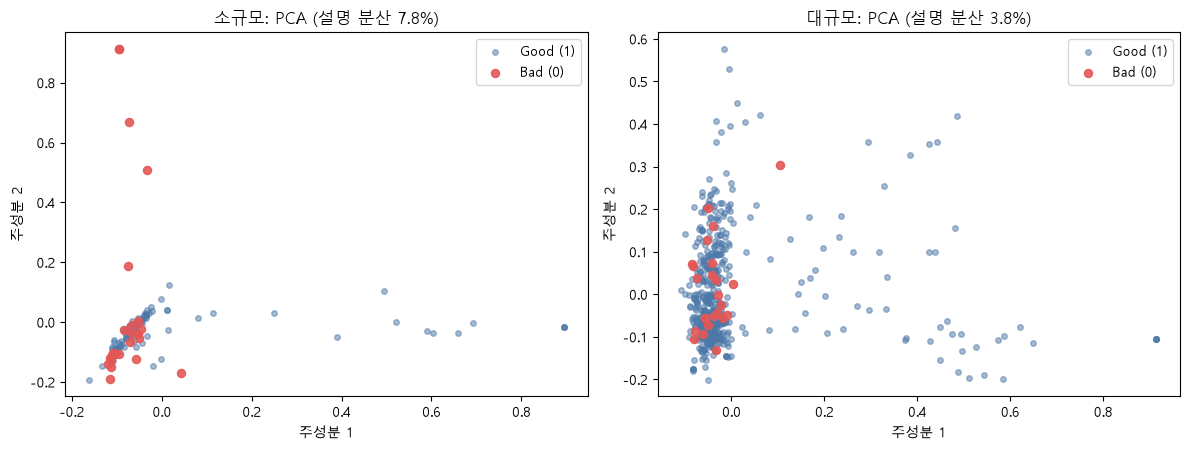

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, d) in zip(axes, data.items()):
    M = TfidfVectorizer(lowercase=True).fit_transform(d["X"]).toarray()
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    Z = pca.fit_transform(M)
    yy = d["y"].to_numpy()
    ax.scatter(Z[yy == 1, 0], Z[yy == 1, 1], s=16, alpha=0.5, c=COLOR["Good"], label="Good (1)")
    ax.scatter(Z[yy == 0, 0], Z[yy == 0, 1], s=34, alpha=0.9, c=COLOR["Bad"], label="Bad (0)")
    ax.set_title(f"{name}: PCA (설명 분산 {pca.explained_variance_ratio_.sum() * 100:.1f}%)")
    ax.set_xlabel("주성분 1")
    ax.set_ylabel("주성분 2")
    ax.legend()
plt.tight_layout()
plt.show()

### 스펙트럴 바이클러스터링

대사(행)와 단어(열)를 동시에 묶어, 비슷한 단어를 쓰는 대사 집단이 나타나는지 본다. 먼저 행과 열을 무작위로 섞은 입력 행렬을 보여 주고, 바이클러스터링으로 재배열한 행렬과 비교한다. 군집 수에는 정답이 없으므로 2~6개를 모두 시도하고, 대사 군집이 실제 라벨(Good/Bad)과 얼마나 일치하는지(ARI, NMI)가 가장 높은 값을 고른다. 이 분석은 라벨을 쓰지 않는 군집이고 설명용이어서 전체 데이터를 사용하며, 소규모 데이터에 적용한다.

In [52]:
from matplotlib.colors import ListedColormap
from sklearn.cluster import SpectralBiclustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

vec_bc = TfidfVectorizer(lowercase=True, min_df=2)
M_bc = vec_bc.fit_transform(data["소규모"]["X"]).toarray()
keep = M_bc.sum(axis=1) > 0
M_bc, y_bc = M_bc[keep], data["소규모"]["y"].to_numpy()[keep]
print(f"행렬 크기: 대사 {M_bc.shape[0]}개 x 단어 {M_bc.shape[1]}개")

rows, models_bc = [], {}
for k in range(2, 7):
    sb = SpectralBiclustering(n_clusters=(k, k), method="bistochastic", random_state=RANDOM_STATE).fit(M_bc)
    models_bc[k] = sb
    rl = sb.row_labels_
    majority_acc = sum(max((y_bc[rl == c] == 0).sum(), (y_bc[rl == c] == 1).sum()) for c in np.unique(rl)) / len(y_bc)
    bad_share = [(y_bc[rl == c] == 0).mean() for c in np.unique(rl)]
    rows.append({"군집 수 (행=열)": k, "ARI": adjusted_rand_score(y_bc, rl), "NMI": normalized_mutual_info_score(y_bc, rl),
                 "군집별 다수 라벨 정확도": majority_acc, "Bad 비율이 가장 높은 군집의 Bad 비율": max(bad_share)})
bc_table = pd.DataFrame(rows).set_index("군집 수 (행=열)")
display(bc_table.round(3))
best_bc_k = int(bc_table["ARI"].idxmax())
print("ARI가 가장 높은 군집 수:", best_bc_k)

행렬 크기: 대사 114개 x 단어 159개


,ARI,NMI,군집별 다수 라벨 정확도,Bad 비율이 가장 높은 군집의 Bad 비율
군집 수 (행=열),,,,
2,0.012,0.043,0.789,0.295
3,0.021,0.073,0.789,0.347
4,-0.036,0.033,0.789,0.277
5,-0.022,0.029,0.789,0.303
6,-0.010,0.030,0.789,0.300


ARI가 가장 높은 군집 수: 3


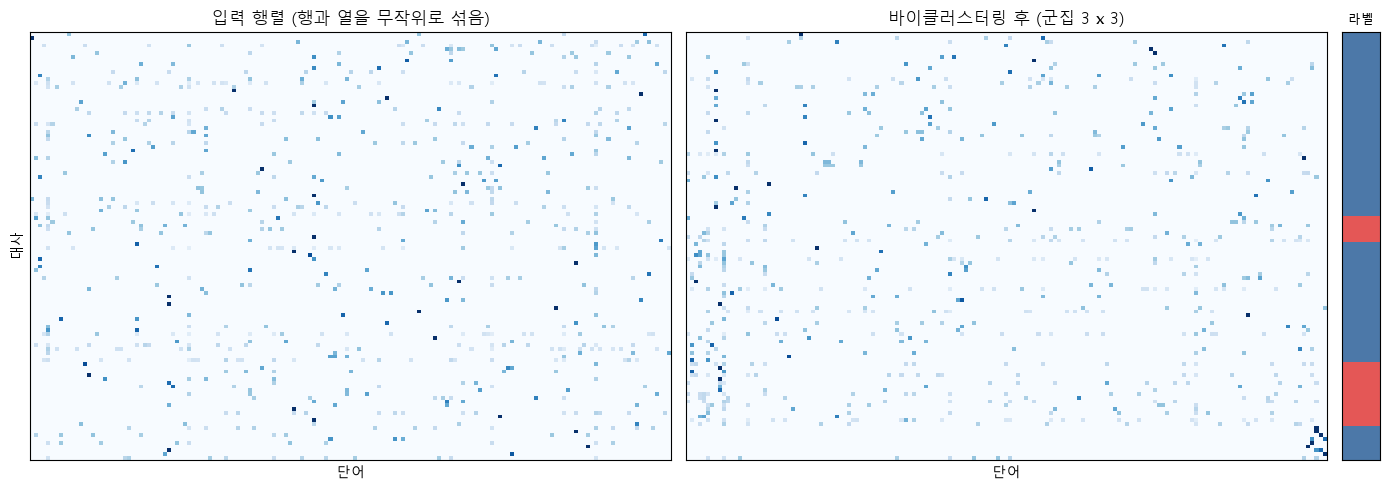

In [53]:
rng = np.random.RandomState(RANDOM_STATE)
row_perm, col_perm = rng.permutation(M_bc.shape[0]), rng.permutation(M_bc.shape[1])
shuffled = M_bc[row_perm][:, col_perm]

sb = models_bc[best_bc_k]
r_order, c_order = np.argsort(sb.row_labels_, kind="stable"), np.argsort(sb.column_labels_, kind="stable")
reordered = M_bc[r_order][:, c_order]

vmax = np.percentile(M_bc[M_bc > 0], 99)
fig, axes = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={"width_ratios": [10, 10, 0.6]})
axes[0].imshow(shuffled, aspect="auto", cmap="Blues", vmax=vmax)
axes[0].set_title("입력 행렬 (행과 열을 무작위로 섞음)")
axes[1].imshow(reordered, aspect="auto", cmap="Blues", vmax=vmax)
axes[1].set_title(f"바이클러스터링 후 (군집 {best_bc_k} x {best_bc_k})")
strip = np.where(y_bc[r_order] == 0, 1, 0)[:, None]
axes[2].imshow(strip, aspect="auto", cmap=ListedColormap([COLOR["Good"], COLOR["Bad"]]))
axes[2].set_title("라벨", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_xlabel("단어"); axes[0].set_ylabel("대사")
axes[1].set_xlabel("단어")
plt.tight_layout()
plt.show()

### 결과 해석 (차원, PCA, 바이클러스터링)

- **차원은 어휘 크기이다.** 소규모는 422차원, 대규모는 1,011차원으로 데이터가 늘수록 새 단어가 생겨 차원이 커진다. 그러나 대사 하나에는 평균 8~9개 단어만 있어 값의 98% 이상이 0인 매우 희소한 행렬이다.
- **PCA 두 성분이 설명하는 분산은 소규모 7.8%, 대규모 3.8%에 불과하다.** 그림에서 Good과 Bad가 거의 겹쳐 있고, 소규모에서 일부 Bad 대사만 따로 떨어져 있다. 2차원 선형 투영만으로는 두 클래스를 가르기 어렵다.
- **바이클러스터링에는 정해진 정답 k가 없다.** 2~6개를 모두 시도한 결과 ARI는 모두 0에 가까웠고(최고 0.021, k=3), 모든 군집의 다수 라벨이 Good이어서 군집 정확도(0.789)는 모두 Good으로 예측했을 때와 같았다. k=3을 보인 것은 ARI가 가장 높았다는 이유뿐이다.
- **섞인 행렬과 재배열한 행렬의 차이도 크지 않다.** 단어가 비슷한 대사끼리 묶이긴 하지만 그 묶음이 Good/Bad와 맞아떨어지지 않는다. 단어 정보만으로 라벨이 구분되기 어렵다는 앞선 모델 결과와 일치한다.

## 최종 모델 선정
### 최종 비교표

지금까지 실행한 모든 실험을 하나의 표로 모았다. 값은 fold 평균이다. 기준선도 함께 넣어 모델 점수가 의미 있는지 비교할 수 있다.

In [54]:
results_overview = master_table()
final_table = results_overview[["데이터 규모", "벡터화", "모델", "불균형 대응", "Accuracy", "Bad Precision", "Bad Recall", "Bad F1", "Macro-F1", "Macro-F1 표준편차"]]
display(final_table.sort_values(["데이터 규모", "Macro-F1"], ascending=[True, False]).round(3).reset_index(drop=True))
results_overview.to_csv(DATA_DIR / "experiment_results.csv", index=False, encoding="utf-8-sig")

,데이터 규모,벡터화,모델,불균형 대응,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1,Macro-F1 표준편차
0,대규모,TF-IDF,Linear SVC,balanced + 튜닝,0.948,0.439,0.393,0.370,0.671,0.108
1,대규모,TF-IDF,Linear SVC,balanced,0.952,0.493,0.324,0.356,0.666,0.098
2,대규모,TF-IDF,Logistic Regression,balanced,0.945,0.422,0.376,0.357,0.664,0.087
3,대규모,TF-IDF,Logistic Regression,balanced + 튜닝,0.943,0.440,0.380,0.341,0.656,0.094
4,대규모,Count,Logistic Regression,balanced,0.942,0.323,0.294,0.298,0.634,0.081
5,대규모,Count,Linear SVC,balanced,0.948,0.335,0.260,0.284,0.628,0.097
6,대규모,TF-IDF,KNN(코사인),기본 + k 탐색,0.951,0.472,0.223,0.282,0.628,0.105
7,대규모,Count,Random Forest,balanced,0.956,0.380,0.140,0.200,0.589,0.102
8,대규모,TF-IDF+SVD,Logistic Regression,balanced,0.866,0.159,0.488,0.236,0.581,0.056
9,대규모,Count,Multinomial NB,balanced,0.878,0.119,0.250,0.159,0.547,0.073


### 선정 기준

과제 계획서에 따라 Accuracy가 아니라 Bad(0) 클래스를 놓치는 비용을 고려해 판단한다.

- 현실적인 불균형을 가진 **대규모 데이터**의 결과를 기준으로 한다.
- Macro-F1 평균이 가장 높은 모델을 중심으로, 최고 점수와의 차이가 0.02 이내인 모델은 사실상 같은 수준으로 보고 그중 **Bad F1이 가장 높은 모델**(같으면 Bad Recall)을 고른다.
- 선택 후 같은 fold 단위로 다른 모델과 짝지어 비교하고, 혼동행렬과 오분류 사례를 확인한다.
- k와 같은 설정을 같은 교차검증 결과로 고른 모델은 점수가 다소 낙관적일 수 있음을 함께 고려한다.

In [55]:
large_tbl = results_overview[(results_overview["데이터 규모"] == "대규모") & (~results_overview["모델"].str.startswith("기준선"))].copy()
top = large_tbl["Macro-F1"].max()
cand = large_tbl[large_tbl["Macro-F1"] >= top - 0.02].sort_values(["Bad F1", "Bad Recall"], ascending=False)
print("최고 Macro-F1:", round(top, 3), "/ 0.02 이내 후보 (Bad F1 순)")
display(cand[["벡터화", "모델", "불균형 대응", "Accuracy", "Bad Precision", "Bad Recall", "Bad F1", "Macro-F1", "Macro-F1 표준편차"]].round(3))

best_row = cand.iloc[0]
best_name = f"{best_row['벡터화']} + {best_row['모델']}" if best_row["벡터화"] != "-" else best_row["모델"]
best_res = None
for (ds, vec, imb), results in experiments.items():
    if ds == "대규모" and imb == best_row["불균형 대응"] and best_name in results:
        best_res = results[best_name]
print("선정된 모델:", best_name, "/", best_row["불균형 대응"])

최고 Macro-F1: 0.671 / 0.02 이내 후보 (Bad F1 순)


,벡터화,모델,불균형 대응,Accuracy,Bad Precision,Bad Recall,Bad F1,Macro-F1,Macro-F1 표준편차
39,TF-IDF,Linear SVC,balanced + 튜닝,0.948,0.439,0.393,0.370,0.671,0.108
21,TF-IDF,Logistic Regression,balanced,0.945,0.422,0.376,0.357,0.664,0.087
22,TF-IDF,Linear SVC,balanced,0.952,0.493,0.324,0.356,0.666,0.098
38,TF-IDF,Logistic Regression,balanced + 튜닝,0.943,0.440,0.380,0.341,0.656,0.094


선정된 모델: TF-IDF + Linear SVC / balanced + 튜닝


In [56]:
# 선정 모델과 다른 주요 모델의 같은 fold 비교 (대규모, Macro-F1 / Bad Recall)
rows = {}
others = {"Logistic Regression (balanced)": results_large_bal["TF-IDF + Logistic Regression"],
          "Linear SVC (balanced)": results_large_bal["TF-IDF + Linear SVC"],
          "길이만 사용 (balanced) 기준선": results_large["기준선: 길이만 사용 (balanced)"]}
for label, res in others.items():
    if res is best_res:
        continue
    for metric in ["Macro-F1", "Bad Recall"]:
        rows[f"{metric}: 선정 모델 - {label}"] = paired_test(best_res, res, metric)
display(pd.DataFrame(rows).T.round(3))

,평균 차이,차이 표준편차,A 우세,B 우세,동점,윌콕슨 p
Macro-F1: 선정 모델 - Logistic Regression (balanced),0.002,0.074,6.0,8.0,1.0,0.875
Bad Recall: 선정 모델 - Logistic Regression (balanced),0.000,0.131,3.0,3.0,9.0,1.000
Macro-F1: 선정 모델 - Linear SVC (balanced),0.009,0.076,5.0,6.0,4.0,0.859
Bad Recall: 선정 모델 - Linear SVC (balanced),0.060,0.159,4.0,1.0,10.0,0.131
Macro-F1: 선정 모델 - 길이만 사용 (balanced) 기준선,0.200,0.122,14.0,1.0,0.0,0.000
Bad Recall: 선정 모델 - 길이만 사용 (balanced) 기준선,-0.270,0.382,3.0,10.0,2.0,0.019


### 혼동행렬과 분류 리포트

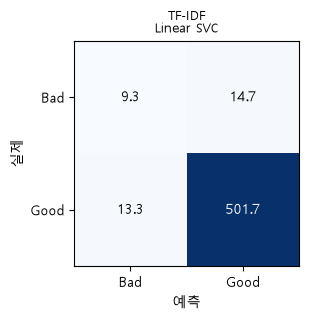

TF-IDF + Linear SVC
              precision    recall  f1-score   support

      Bad(0)      0.368     0.292     0.326        24
     Good(1)      0.967     0.977     0.972       515

    accuracy                          0.946       539
   macro avg      0.668     0.634     0.649       539
weighted avg      0.941     0.946     0.943       539



In [57]:
plot_confusion({best_name: best_res}, "대규모", names=[best_name])
print_reports({best_name: best_res}, "대규모")

### 오분류 사례

선정 모델이 반복 실험에서 얼마나 자주 틀렸는지(오분류 비율)를 대사별로 계산했다. 비율이 높을수록 일관되게 틀리는 대사이다.

In [58]:
y_l = data["대규모"]["y"].to_numpy()
err_rate = np.mean([best_res["oof"][s] != y_l for s in best_res["oof"]], axis=0)
err_df = pd.DataFrame({"캐릭터": clean["대규모"]["CharacterName_Clean"], "실제": clean["대규모"]["Label"],
                       "대사": clean["대규모"]["Text"].str.slice(0, 110), "오분류 비율": err_rate})
bad_df = err_df[err_df["실제"] == "Bad"]
print(f"Bad 대사 {len(bad_df)}개 중 매번 맞힌 대사: {(bad_df['오분류 비율'] == 0).sum()}개 / 매번 놓친 대사: {(bad_df['오분류 비율'] == 1).sum()}개")
print("\n[Bad인데 Good으로 예측한 대사 (놓친 Bad)]")
display(bad_df.sort_values("오분류 비율", ascending=False).head(6))
print("[Good인데 Bad로 예측한 대사 (잘못 의심한 Good)]")
display(err_df[err_df["실제"] == "Good"].sort_values("오분류 비율", ascending=False).head(6))
print("[참고] Bad를 일관되게 맞힌 대사")
display(bad_df.sort_values("오분류 비율").head(4))

Bad 대사 24개 중 매번 맞힌 대사: 5개 / 매번 놓친 대사: 10개

[Bad인데 Good으로 예측한 대사 (놓친 Bad)]


,캐릭터,실제,대사,오분류 비율
167,EMPEROR,Bad,"Strange, that I have not. I wonder if your feelings on this matter are clear, Lord Vader.",1.0
232,EMPEROR,Bad,Then you must go to the Sanctuary Moon and wait for them.,1.0
443,EMPEROR,Bad,He will not permit anyone but me to see him. You must be outside this room.... Do what you can.,1.0
480,EMPEROR,Bad,Everything is proceeding as I have foreseen.,1.0
519,EMPEROR,Bad,I can assure you...,1.0
508,EMPEROR,Bad,I shall want telepathy during his visit and a report when we're finished.,1.0


[Good인데 Bad로 예측한 대사 (잘못 의심한 Good)]


,캐릭터,실제,대사,오분류 비율
40,LEIA,Good,Yes.,1.000000
285,LEIA,Good,"Yes, you do.",1.000000
353,LUKE,Good,Yes. It's you Leia.,1.000000
84,LUKE,Good,I am the son of Annikin Starkiller.,0.666667
77,LUKE,Good,Lord Vader ... Is the dark side stronger?,0.666667
136,LEIA,Good,We should have stayed and finished them off.,0.666667


[참고] Bad를 일관되게 맞힌 대사


,캐릭터,실제,대사,오분류 비율
240,EMPEROR,Bad,Yes.,0.0
403,EMPEROR,Bad,Yes ... yes. That would be a great asset.,0.0
414,EMPEROR,Bad,It is of no concern. Soon the Rebellion will be crushed and young Skywalker will be one of us! Your work h...,0.0
253,EMPEROR,Bad,Yes?,0.0


### 모델이 학습한 단어

전체 대규모 데이터로 학습한 Logistic Regression(balanced)의 계수를 보고, 어떤 단어가 Bad 또는 Good 판단에 가장 크게 기여하는지 확인한다. 설명용 학습이며 성능 평가에는 사용하지 않는다.

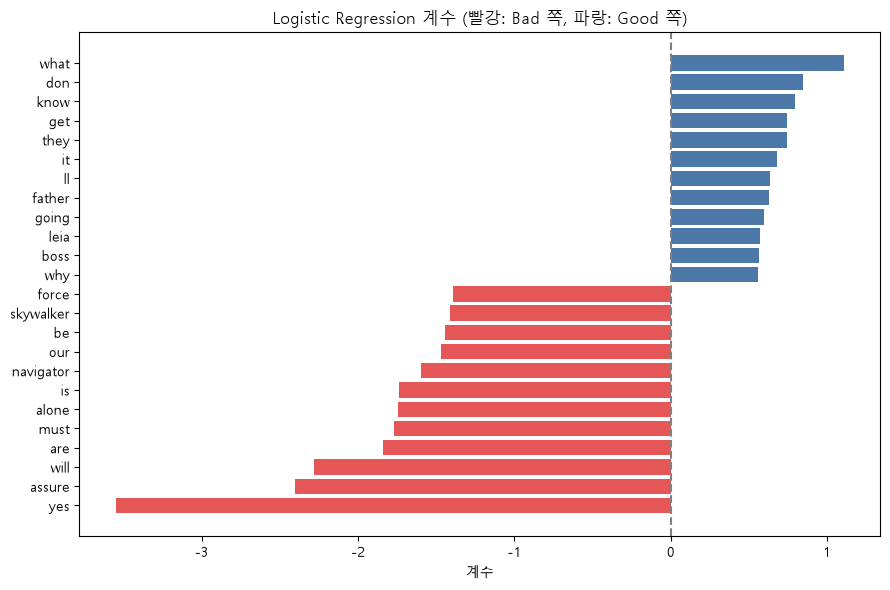

Bad 쪽 상위 단어: ['yes', 'assure', 'will', 'are', 'must', 'alone', 'is', 'navigator', 'our', 'be', 'skywalker', 'force']
Good 쪽 상위 단어: ['what', 'don', 'know', 'get', 'they', 'it', 'll', 'father', 'going', 'leia', 'boss', 'why']


In [59]:
vec_w = TfidfVectorizer(lowercase=True)
Xw = vec_w.fit_transform(data["대규모"]["X"])
lr_w = LogisticRegression(C=1.0, solver="liblinear", class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE).fit(Xw, data["대규모"]["y"])
words = np.array(vec_w.get_feature_names_out())
order = np.argsort(lr_w.coef_[0])
top_bad_w, top_good_w = order[:12], order[-12:]
idx = np.hstack([top_bad_w, top_good_w])
plt.figure(figsize=(9, 6))
plt.barh(words[idx], lr_w.coef_[0][idx], color=[COLOR["Bad"] if c < 0 else COLOR["Good"] for c in lr_w.coef_[0][idx]])
plt.axvline(0, color="gray", linestyle="--")
plt.title("Logistic Regression 계수 (빨강: Bad 쪽, 파랑: Good 쪽)")
plt.xlabel("계수")
plt.tight_layout()
plt.show()
print("Bad 쪽 상위 단어:", list(words[top_bad_w]))
print("Good 쪽 상위 단어:", list(words[top_good_w][::-1]))

### 결과 해석 (최종 모델)

**선정 결과:** TF-IDF + Linear SVC(balanced, 하이퍼파라미터 탐색)가 대규모 데이터에서 Macro-F1 0.671 ± 0.108, Bad Precision 0.439, Bad Recall 0.393, Bad F1 0.370으로 선정 규칙을 통과했다.

- **그러나 Logistic Regression과 구분되지 않는다.** 같은 fold 비교에서 Macro-F1 차이가 +0.002(p = 0.875), 탐색하지 않은 Linear SVC와는 +0.009(p = 0.859)이다. 어느 한쪽이 확실히 낫다고 말할 수는 없으며, 단순함을 중시하면 탐색하지 않은 Logistic Regression(표준편차 0.087로 가장 안정적, Bad Recall 0.376)도 타당한 선택이다.
- **길이만 쓴 기준선보다는 분명히 낫다.** Macro-F1이 평균 0.200 높고 15개 fold 중 14개에서 앞섰다. 다만 길이 기준선은 Bad Recall이 0.668로 더 높고 Precision이 0.086으로 매우 낮다.
- **Accuracy가 오히려 불리해 보인다.** 선정 모델의 Accuracy는 평균 0.948로 모두 Good으로 예측하는 기준선(0.955)보다 낮다. Bad를 찾으려는 대가로 Good을 Bad로 잘못 부르는 오류가 생기기 때문이며, 이 과제에서 Accuracy만으로 모델을 고르면 안 되는 이유이다.
- **혼동행렬(첫 번째 반복):** Bad 24개 중 7개를 찾았고(Recall 0.292, Precision 0.368, F1 0.326), Good은 515개 중 약 503개를 맞혔다.

**오분류 사례 (선정 모델)**

| 대사 | 실제 | 예측 | 추정 원인 |
|---|---|---|---|
| Everything is proceeding as I have foreseen. | Bad | Good | 일반적인 단어로만 이루어져 Bad를 특징짓는 단어가 없다. |
| I shall want telepathy during his visit and a report when we're finished. | Bad | Good | 영화 '듄' 대사로 보이며, 학습 데이터에 없는 어휘라 단서가 없다. |
| I can assure you... | Bad | Good | 매우 짧은 대사라 정보가 부족하다. |
| Yes. (LEIA) | Good | Bad | 'yes'가 가장 강한 Bad 단어로 학습되었다. 황제의 대사에 'Yes'가 많기 때문으로 보인다. |
| Vader is here...now, on this moon. (LUKE) | Good | Bad | 'Vader'가 들어 있어 황제 대사와 비슷하게 보인다. |

**모델이 학습한 단어:** Bad 쪽 상위 단어는 yes, assure, must, navigator, skywalker, force 등이고, Good 쪽은 what, don, know, get, why, father, leia, boss 등이다. Bad 쪽에는 격식 있는 말투와 황제의 대사에 반복되는 어휘, 그리고 '듄'의 navigator가 섞여 있고, Good 쪽에는 질문과 축약형(don, ll) 같은 구어체와 다른 영화의 단어(boss)가 있다. 모델이 '선한 대사'가 아니라 말투와 영화별 어휘를 단서로 쓴다는 의미이다.

## 한계와 개선 방안

**한계**

- Bad 표본이 24개이고 모두 EMPEROR이다. DARTH VADER가 없어서 'Bad 대사'가 아니라 '황제의 말투'를 학습한 것이다.
- 스타워즈가 아닌 영화의 대사가 섞여 있고, 대사 길이와 영화별 어휘가 라벨과 얽혀 있다.
- 대규모 데이터는 Good만 늘어 불균형이 심해졌고(약 4:1에서 약 21.5:1), 데이터가 늘었는데도 성능은 오히려 낮아졌다.
- 모든 지표는 Bad 24개에 기댄 교차검증 평균이라 표준편차가 크고, 모델 간 작은 차이는 구분되지 않는다.
- 하이퍼파라미터 탐색과 KNN의 k 선택은 같은 데이터 안에서 이루어졌다(중첩 검증으로 완화).
- 사전학습 문장 임베딩과 생성형 모델은 실행하지 못했다.
- 캐릭터 기준 라벨은 과제용 규칙이므로 결과를 일반적인 감정 분석 성능으로 해석하지 않는다.

**개선 방안**

- 원본 Cornell 코퍼스에서 영화를 스타워즈로 제한하고 VADER를 포함해 Bad 표본을 늘린다(최소 100~200개).
- 이전 2~3개 턴의 대사를 함께 넣어 문맥 정보를 반영한다.
- 길이와 영화별 어휘의 영향을 확인하는 대조 실험(길이 통제, 타 영화 대사 제거)을 한다.
- Sentence-BERT 임베딩과 소형 LLM의 분류 결과를 같은 분할에서 비교한다.
- 동일 화자의 대사를 통째로 같은 fold에 두는 화자 단위 분할로 일반화 성능을 점검한다.